In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from visualization import (
    plot_cost_function_with_minima, 
    plot_ploidy_optimization,
    plot_ploidy_comparison,  # Add this
    print_overlap_matrix, 
    plot_overlap_matrix_figure,
    plot_uniformity_histograms_nice
)
from copy_number import (
    make_unif_dict, 
    compute_read_counts_relative_to_normal,
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)

import time

/home/ranade/miniconda3/lib/python3.6/site-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


In [2]:
numb = "57"
tumor = "t"+numb

In [3]:
bincounts = pd.read_csv(f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt", sep = "\t")
bincounts_no_WGS = pd.read_csv(f"../data/{tumor}/{tumor}.bincounts_without_WGS_segmentation.txt", sep="\t")
cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values
#normal_cells = pd.read_csv(f"../data/{tumor}/normal_cells.txt", header=None, sep="\t")[0].values

In [4]:
bincounts[bincounts["chrom"]=="chr19"]

,chrom,loc.start,loc.end,abstart,abend,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,...,TTTTGGAGTTTGCGTCT,TTTTGGATTCCTAGAGA,TTTTGGGAACAATAAGC,TTTTGGGGGTTTTCAGA,TTTTGGGTCTTTAGTCG,TTTTGGGTCTTTCTACT,TTTTGGTAAGCTCAAGT,TTTTGGTGCAGGAATCA,TTTTGGTGCAGGAGAAG,TTTTGGTTTGGAAGTAC
78,chr19,0,56806255,2659444323,2716250578,650,1300,415,1516,988,...,567,1361,692,984,1756,1897,851,1067,308,934
79,chr19,57365282,58522984,2716809605,2717967307,13,35,12,22,14,...,9,43,13,18,27,31,27,17,0,20


In [5]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t")
B_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t")
C_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t")
D_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D.txt", sep="\t")
equi_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_equi_bins.txt", sep="\t")
#C_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_C_WGS_with_broken_cells.txt", sep="\t")

In [6]:
A_df.head()

,cell,population,normal_population
0,AAAACCAGCTTAGATAC,A11,False
1,AAAACCTAAACCAGACT,A11,False
2,AAAACCTAACCAACACA,A11,False
3,AAAACCTTGAGCATTGG,A11,False
4,AAAATGCTTCCAAGTAC,A11,False


In [7]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }


A11
A121
A122
A21
A22


In [8]:
B_dict = {}
for cluster in B_df['population'].unique():
    print(cluster)
    cells_in_cluster = B_df[B_df['population'] == cluster]['cell'].tolist()
    B_dict[cluster] = {
        'cells': cells_in_cluster
    }

B1111
B1112
B1121
B1122
B121
B122
B21
B221
B222


In [9]:
C_dict = {}
for cluster in C_df['population'].unique():
    print(cluster)
    cells_in_cluster = C_df[C_df['population'] == cluster]['cell'].tolist()
    C_dict[cluster] = {
        'cells': cells_in_cluster
    }

C11
C12
C211
C212
C2211
C22121
C22122
C2221
C2222


In [10]:
D_dict = {}
for cluster in D_df['population'].unique():
    print(cluster)
    cells_in_cluster = D_df[D_df['population'] == cluster]['cell'].tolist()
    D_dict[cluster] = {
        'cells': cells_in_cluster
    }

D11
D12
D211
D2121
D2122
D221
D222


In [11]:
# equi_dict = {}
# for cluster in equi_df['population'].unique():
#     print(cluster)
#     cells_in_cluster = equi_df[equi_df['population'] == cluster]['cell'].tolist()
#     equi_dict[cluster] = {
#         'cells': cells_in_cluster
#     }

In [12]:
#overlap_df = print_overlap_matrix(A_dict, equi_dict, name1="WGS bins - ", name2="equi-partitioned bins -")

In [13]:
# new_order = []
# for col in overlap_df.columns:
#     #Find the index of the maximum value in the column
#     max_index = overlap_df[col].idxmax()
#     if max_index not in new_order:
#         new_order.append(max_index)

# for row in overlap_df.index:
#     if row not in new_order:
#         new_order.append(row)
# new_order_dict = {k: A_dict[k] for k in new_order}
    

In [14]:
cluster_counts = bincounts[["chrom", "abstart", "abend"]].copy()
for cluster in A_dict.keys():
    cells_in_cluster = A_dict[cluster]['cells']
    cluster_counts[cluster] = bincounts[cells_in_cluster].sum(axis=1)

In [15]:
cluster_counts.to_csv(f"../data/{tumor}/{tumor}_cluster_counts_A_WGS_bins.txt", sep="\t", index=False)

In [16]:
#overlap_df = plot_overlap_matrix_figure(A_dict, equi_dict, name1="WGS bins", name2="equi-partitioned bins")


Overlap Matrix (A rows vs B cols):
Pop        B1111   B1112   B1121   B1122    B121    B122     B21    B221    B222
A11           47     243      23      80       0       0       0       0       0
A121           0       0       0       0     136       0       0       0       0
A122           0       0       1       0       0     209       0       0       0
A21            0       0       1       0       0       0       1      90    1513
A22            2       0      19       0       0       0      64       1       0


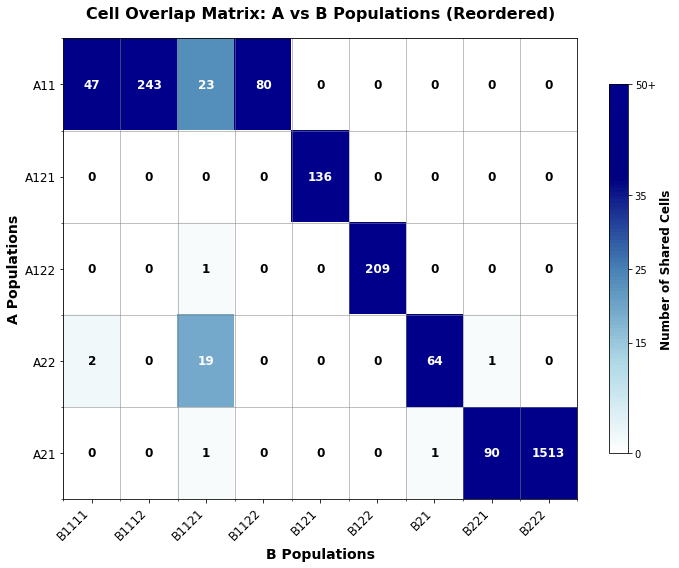

In [17]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict, name1="A", name2="B")


Overlap Matrix (A rows vs B cols):
Pop          C11     C12    C211    C212   C2211  C22121  C22122   C2221   C2222
A11            0       0       0       0     160      34      98      21      80
A121           0       0     136       0       0       0       0       0       0
A122           0       0       0     209       0       0       0       1       0
A21         1603       1       0       0       0       0       0       1       0
A22            0      65       0       0       0       1       0      20       0


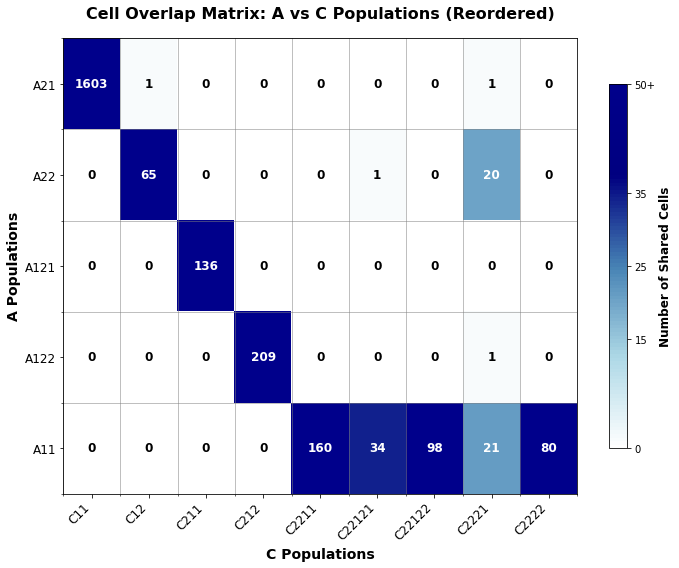

In [18]:
overlap_df = plot_overlap_matrix_figure(A_dict, C_dict, name1="A", name2="C")


Overlap Matrix (A rows vs B cols):
Pop          C11     C12    C211    C212   C2211  C22121  C22122   C2221   C2222
B1111          0       0       0       0       0      35      12       1       1
B1112          0       0       0       0     160       0      83       0       0
B1121          0       0       0       0       0       0       2      42       0
B1122          0       0       0       0       0       0       1       0      79
B121           0       0     136       0       0       0       0       0       0
B122           0       0       0     209       0       0       0       0       0
B21            0      65       0       0       0       0       0       0       0
B221          90       1       0       0       0       0       0       0       0
B222        1513       0       0       0       0       0       0       0       0


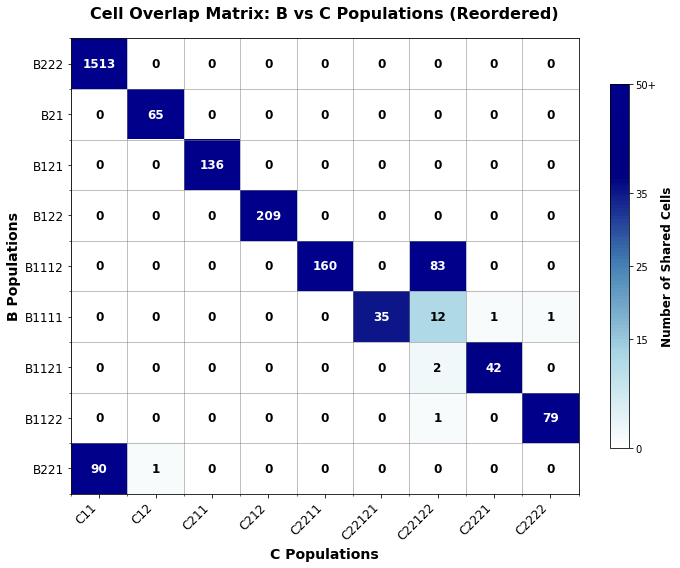

In [19]:
overlap_df = plot_overlap_matrix_figure(B_dict, C_dict, name1="B", name2="C")


Overlap Matrix (A rows vs B cols):
Pop          D11     D12    D211   D2121   D2122    D221    D222
C11         1603       0       0       0       0       0       0
C12            1      65       0       0       0       0       0
C211           0       0       0       0       0     135       1
C212           0       0       0       0       0       0     209
C2211          0       0     159       0       1       0       0
C22121         0       0      32       3       0       0       0
C22122         0       0      94       3       1       0       0
C2221          0       0       0      43       0       0       0
C2222          0       0       0       0      80       0       0


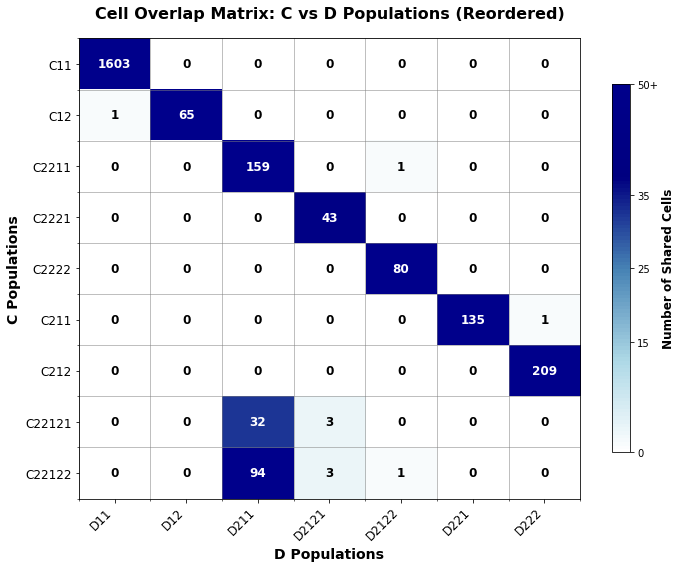

In [20]:
overlap_df = plot_overlap_matrix_figure(C_dict, D_dict, name1="C", name2="D")

In [21]:
# Prepare the data - create the data DataFrame with segment info
data = bincounts[["chrom","abstart", "abend"]].copy()
data_no_WGS = bincounts_no_WGS[["chrom","abstart", "abend"]].copy()
for cell in cells:
    if cell in bincounts.columns:
        data[cell] = bincounts[cell].values
        data_no_WGS[cell] = bincounts_no_WGS[cell].values
data["lengths"] = data["abend"] - data["abstart"]
data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]

# Get just the cell count data for analysis
all_data = data[cells].copy()
all_data_no_WGS = data_no_WGS[cells].copy()

In [22]:
# Identify normal populations and compute ratios for both A and B populations
print("=== Population Set A Analysis ===")
avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)
print("=== Population Set B Analysis ===")
avg_counts_B, ratios_B, normal_B = compute_average_segment_counts(all_data, B_dict, data)
relative_counts_B = compute_read_counts_relative_to_normal(all_data, B_dict, normal_B)
print("=== Population Set C Analysis ===")
avg_counts_C, ratios_C, normal_C = compute_average_segment_counts(all_data, C_dict, data)
relative_counts_C = compute_read_counts_relative_to_normal(all_data, C_dict, normal_C)
print("=== Population Set D Analysis ===")
avg_counts_D, ratios_D, normal_D = compute_average_segment_counts(all_data, D_dict, data)
relative_counts_D = compute_read_counts_relative_to_normal(all_data, D_dict, normal_D)



=== Population Set A Analysis ===
Normal population identified as: A21
Mean read count ratio for population A11 relative to normal (A21): 1.28
Mean read count ratio for population A121 relative to normal (A21): 1.12
Mean read count ratio for population A122 relative to normal (A21): 1.20
Mean read count ratio for population A21 relative to normal (A21): 1.00
Mean read count ratio for population A22 relative to normal (A21): 1.24
=== Population Set B Analysis ===
Normal population identified as: B222
Mean read count ratio for population B1111 relative to normal (B222): 1.29
Mean read count ratio for population B1112 relative to normal (B222): 1.29
Mean read count ratio for population B1121 relative to normal (B222): 1.33
Mean read count ratio for population B1122 relative to normal (B222): 1.24
Mean read count ratio for population B121 relative to normal (B222): 1.13
Mean read count ratio for population B122 relative to normal (B222): 1.20
Mean read count ratio for population B21 relati

In [23]:
#Add normal to the A_df population assignments
A_df["normal_population"] = (A_df['population'] == normal_A)
B_df["normal_population"] = (B_df['population'] == normal_B)
C_df["normal_population"] = (C_df['population'] == normal_C)
D_df["normal_population"] = (D_df['population'] == normal_D)

In [24]:
# A_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t", index = False)
# B_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t", index = False)
# C_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t", index = False)
# D_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D.txt", sep="\t", index = False)

In [25]:
# A_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t")
# A_dict = {}
# for cluster in A_df['population'].unique():
#     print(cluster)
#     cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
#     A_dict[cluster] = {
#         'cells': cells_in_cluster
#     }
# avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
# relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)

In [26]:
data_lengths = data["abend"] - data["abstart"]

Computing uniformity data using make_unif_dict...


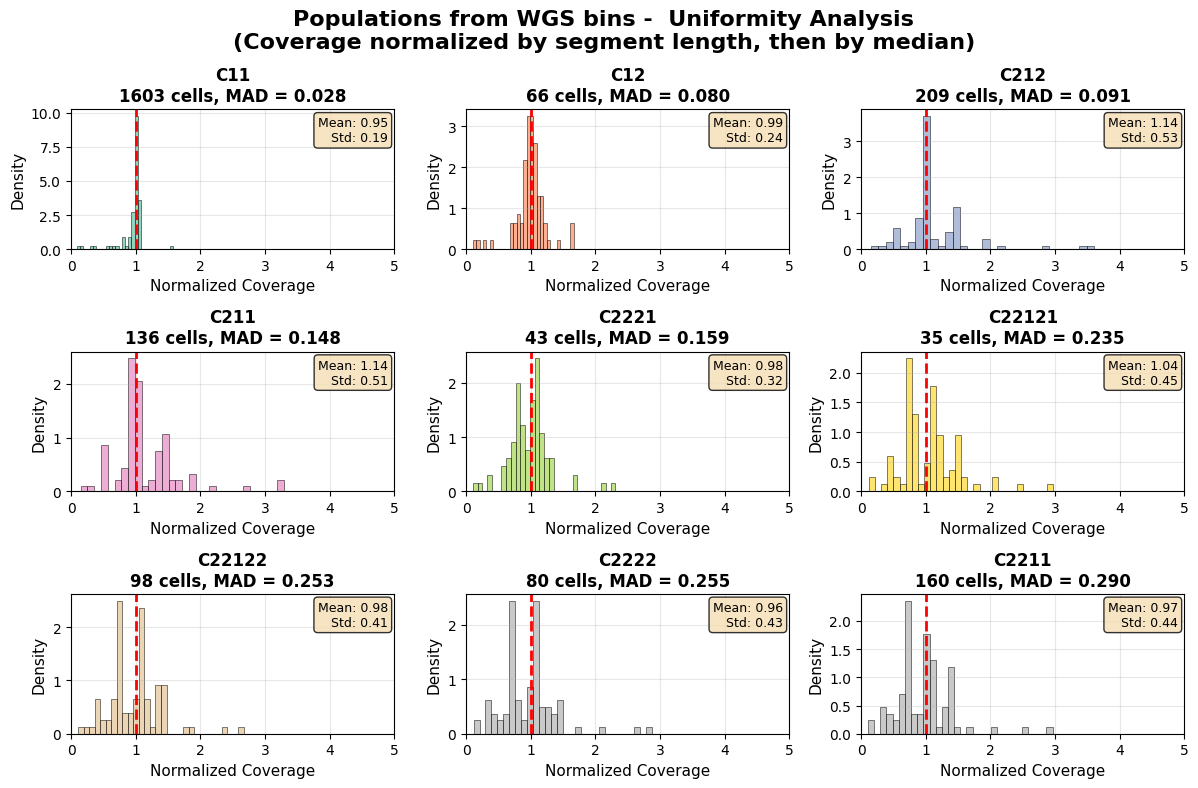


Populations from WGS bins -  Uniformity Summary:
Population   Cells    MAD      Mean     Std     
------------------------------------------------------------
C11          1603     0.028    0.95     0.19    
C12          66       0.080    0.99     0.24    
C212         209      0.091    1.14     0.53    
C211         136      0.148    1.14     0.51    
C2221        43       0.159    0.98     0.32    
C22121       35       0.235    1.04     0.45    
C22122       98       0.253    0.98     0.41    
C2222        80       0.255    0.96     0.43    
C2211        160      0.290    0.97     0.44    

Identified normal population: C11 (lowest MAD = 0.028)


({'C11': 0     1.011298
  1     1.016801
  2     0.677976
  3     1.027582
  4     1.000088
          ...   
  84    1.041053
  85    1.021076
  86    0.999184
  87    0.879177
  88    0.985568
  Length: 89, dtype: float64, 'C12': 0     0.980478
  1     1.246685
  2     0.805566
  3     1.120980
  4     0.962430
          ...   
  84    1.003624
  85    1.132243
  86    1.174189
  87    1.000456
  88    0.956741
  Length: 89, dtype: float64, 'C211': 0     0.987765
  1     1.906825
  2     1.009522
  3     1.447314
  4     0.950300
          ...   
  84    0.859463
  85    1.416931
  86    1.912570
  87    1.360463
  88    1.006233
  Length: 89, dtype: float64, 'C212': 0     0.995658
  1     1.905872
  2     1.019442
  3     1.082528
  4     0.981097
          ...   
  84    0.848793
  85    1.419079
  86    1.405654
  87    1.243382
  88    0.951342
  Length: 89, dtype: float64, 'C2211': 0     0.801277
  1     1.457794
  2     1.297413
  3     1.419464
  4     0.698562
          ...   

In [27]:
plot_uniformity_histograms_nice(
    all_data, 
    C_dict, 
    data_lengths, 
    uniformity_data=None,  # Optional: will compute if not provided
    title_prefix="Populations from WGS bins - ", 
    figsize=(12, 8)
)

Computing uniformity data using make_unif_dict...


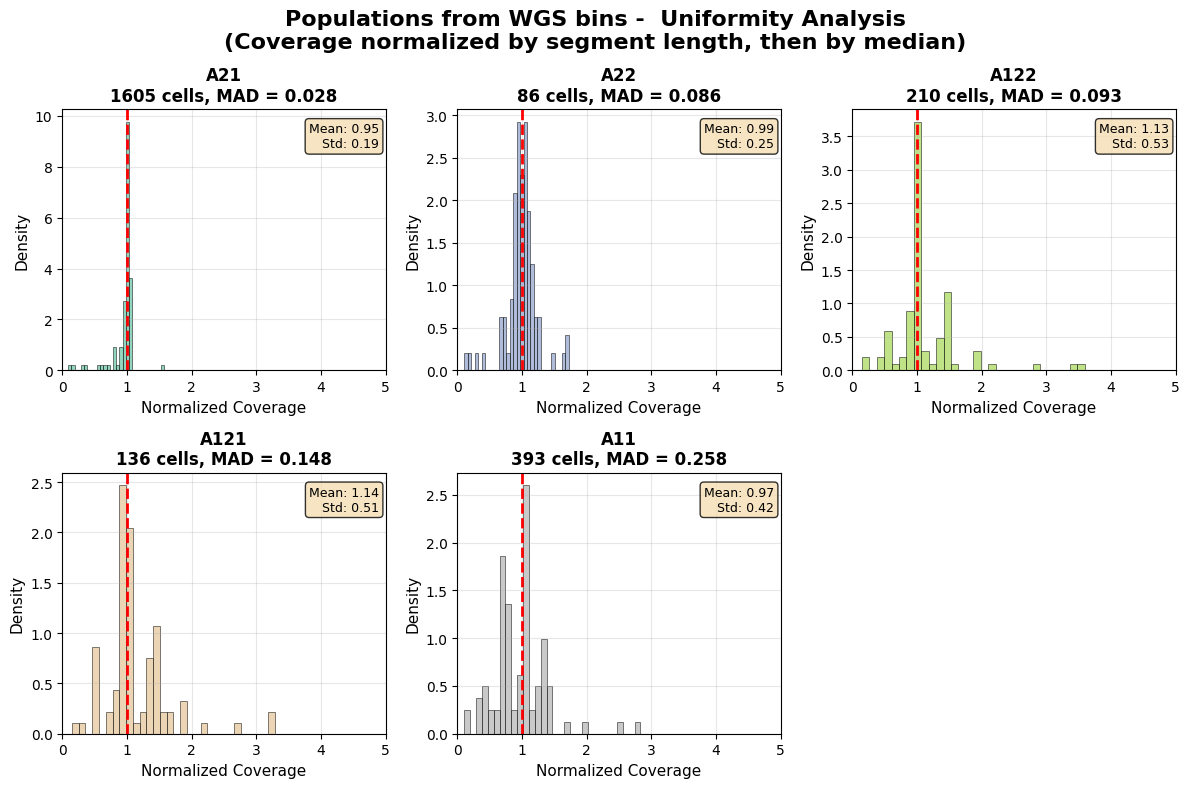


Populations from WGS bins -  Uniformity Summary:
Population   Cells    MAD      Mean     Std     
------------------------------------------------------------
A21          1605     0.028    0.95     0.19    
A22          86       0.086    0.99     0.25    
A122         210      0.093    1.13     0.53    
A121         136      0.148    1.14     0.51    
A11          393      0.258    0.97     0.42    

Identified normal population: A21 (lowest MAD = 0.028)


({'A11': 0     0.772138
  1     1.422574
  2     1.268256
  3     1.468672
  4     0.743926
          ...   
  84    0.636198
  85    1.044179
  86    1.090885
  87    1.227428
  88    1.030895
  Length: 89, dtype: float64, 'A121': 0     0.987765
  1     1.906825
  2     1.009522
  3     1.447314
  4     0.950300
          ...   
  84    0.859463
  85    1.416931
  86    1.912570
  87    1.360463
  88    1.006233
  Length: 89, dtype: float64, 'A122': 0     0.989313
  1     1.897005
  2     1.021533
  3     1.084685
  4     0.974257
          ...   
  84    0.847762
  85    1.414763
  86    1.397725
  87    1.239646
  88    0.946681
  Length: 89, dtype: float64, 'A21': 0     1.011262
  1     1.016786
  2     0.677984
  3     1.027631
  4     1.000000
          ...   
  84    1.040958
  85    1.021036
  86    0.999179
  87    0.879248
  88    0.985548
  Length: 89, dtype: float64, 'A22': 0     0.968326
  1     1.261172
  2     0.889195
  3     1.187882
  4     0.944689
          ...   
 

In [28]:
plot_uniformity_histograms_nice(
    all_data, 
    A_dict, 
    data_lengths, 
    uniformity_data=None,  # Optional: will compute if not provided
    title_prefix="Populations from WGS bins - ", 
    figsize=(12, 8)
)

In [29]:
# Display the ratios dataframes
print("Population A ratios:")
print(ratios_A.head())

print("\nPopulation B ratios:")
print(ratios_B.head())

Population A ratios:
  chrom      start        end  segment_id  A11_ratio  A121_ratio  A122_ratio  \
0  chr1          0   45387037           0   0.963484    0.918880    0.985853   
1  chr1   45972336  119478274           1   1.765462    1.764209    1.880099   
2  chr1  120035598  175362842           2   2.360481    1.400764    1.518359   
3  chr1  175900450  182029442           3   1.803436    1.324934    1.063673   
4  chr1  182578512  248389233           4   0.938735    0.893984    0.981782   

   A21_ratio  A22_ratio  
0        1.0   1.138342  
1        1.0   1.474550  
2        1.0   1.559166  
3        1.0   1.374203  
4        1.0   1.123062  

Population B ratios:
  chrom      start        end  segment_id  B1111_ratio  B1112_ratio  \
0  chr1          0   45387037           0     0.934772     0.991062   
1  chr1   45972336  119478274           1     1.753482     1.815688   
2  chr1  120035598  175362842           2     2.046119     2.459958   
3  chr1  175900450  182029442       

In [30]:
relative_counts_A

{'A11': 1.2782278377837493,
 'A121': 1.1249778959549253,
 'A122': 1.196189461934024,
 'A21': 1.0,
 'A22': 1.2381445255560044}

In [31]:
# Get all population ratio columns (excluding normal population) for A
pop_ratio_cols_A = [col for col in ratios_A.columns if col.endswith('_ratio') and col != f"{normal_A}_ratio"]

# Store results
ploidy_results_A = {}
profile_dfs_A = {}

print(f"Normal population: {normal_A}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_A]}")

for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")

Normal population: A21
Populations to optimize: ['A11', 'A121', 'A122', 'A22']

Optimizing ploidy for population: A11
Target multiplier based on relative counts: 2.56

Optimal Results for A11:
Optimal multiplier (m): 2.300
Minimum cost: 2.58e+08
Average copy number: 2.32
Found 4 local minima
Optimal multiplier for A11: 2.300

Optimizing ploidy for population: A121
Target multiplier based on relative counts: 2.25

Optimal Results for A121:
Optimal multiplier (m): 2.500
Minimum cost: 4.97e+07
Average copy number: 2.51
Found 3 local minima
Optimal multiplier for A121: 2.500

Optimizing ploidy for population: A122
Target multiplier based on relative counts: 2.39

Optimal Results for A122:
Optimal multiplier (m): 2.500
Minimum cost: 3.00e+07
Average copy number: 2.48
Found 3 local minima
Optimal multiplier for A122: 2.500

Optimizing ploidy for population: A22
Target multiplier based on relative counts: 2.48

Optimal Results for A22:
Optimal multiplier (m): 2.000
Minimum cost: 1.31e+08
Aver

In [32]:
# In your existing ploidy optimization loop, just modify the function call:
for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Get local minima along with the usual results
    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1, 
        find_local_minima=True,  # Add this parameter
        window_size=2           # Optional: adjust window size
    )
    
    # Store results including local minima
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima  # Add this
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")


Optimizing ploidy for population: A11
Target multiplier based on relative counts: 2.56

Optimal Results for A11:
Optimal multiplier (m): 2.300
Minimum cost: 2.58e+08
Average copy number: 2.32
Found 4 local minima
Optimal multiplier for A11: 2.300
Found 4 local minima: ['2.90', '3.90', '5.30', '2.30']

Optimizing ploidy for population: A121
Target multiplier based on relative counts: 2.25

Optimal Results for A121:
Optimal multiplier (m): 2.500
Minimum cost: 4.97e+07
Average copy number: 2.51
Found 3 local minima
Optimal multiplier for A121: 2.500
Found 3 local minima: ['2.50', '5.10', '3.70']

Optimizing ploidy for population: A122
Target multiplier based on relative counts: 2.39

Optimal Results for A122:
Optimal multiplier (m): 2.500
Minimum cost: 3.00e+07
Average copy number: 2.48
Found 3 local minima
Optimal multiplier for A122: 2.500
Found 3 local minima: ['2.50', '5.00', '3.60']

Optimizing ploidy for population: A22
Target multiplier based on relative counts: 2.48

Optimal Resu


Plotting results for population: A21


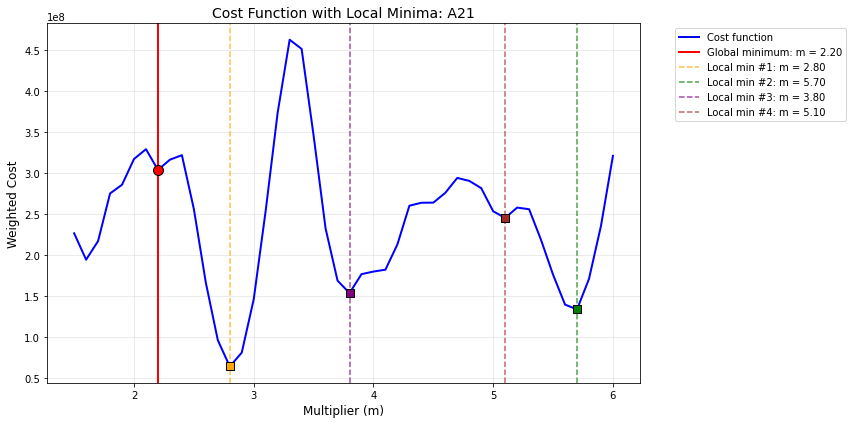


Local Minima Summary for A21:
--------------------------------------------------
#1: m = 2.80, cost = 6.39e+07
#2: m = 5.70, cost = 1.34e+08
#3: m = 3.80, cost = 1.54e+08
#4: m = 5.10, cost = 2.45e+08
#5: m = 2.20, cost = 3.04e+08 (GLOBAL)


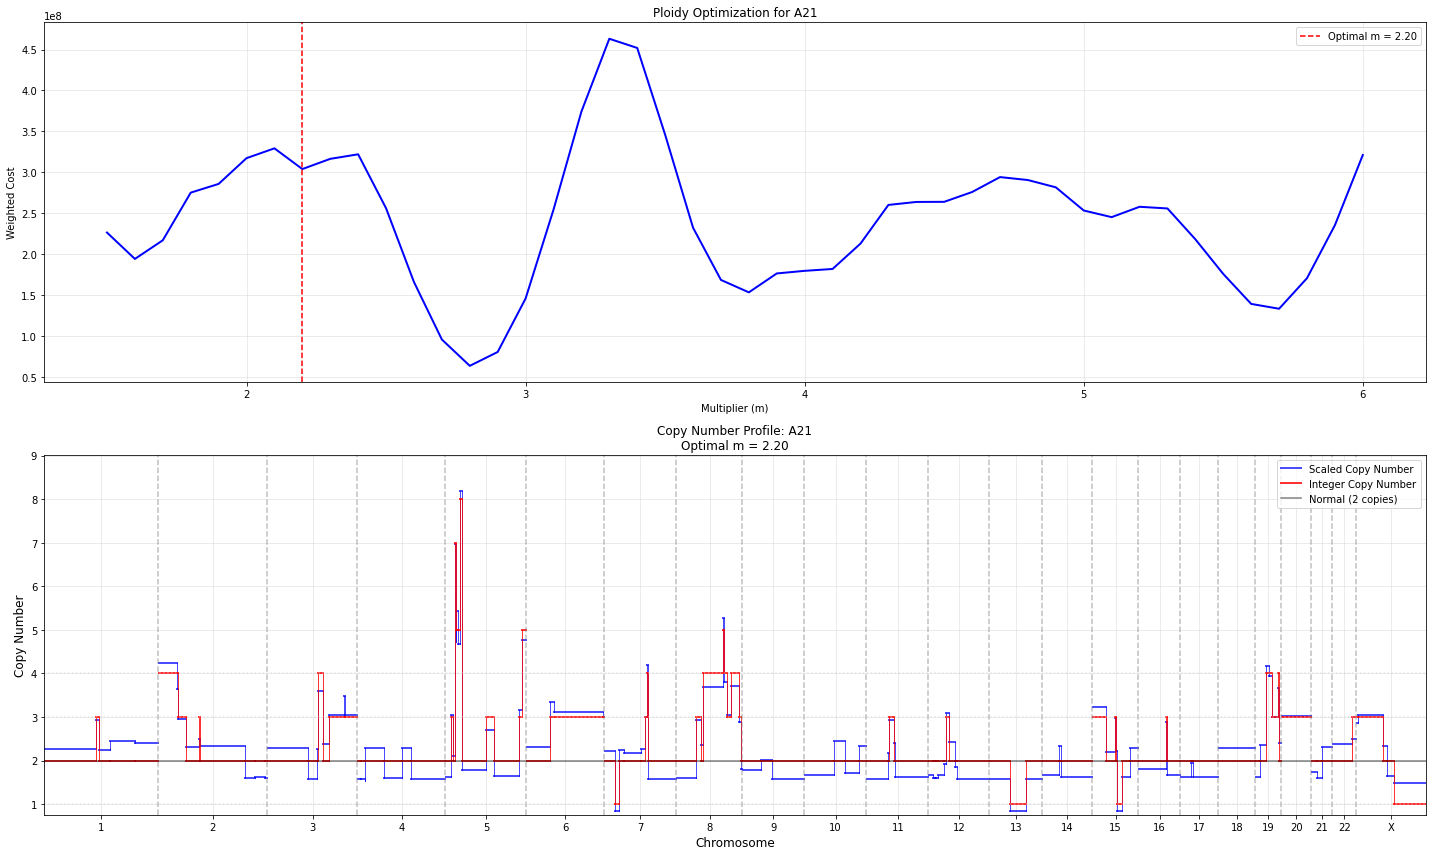

Completed plots for A21

Plotting results for population: A221


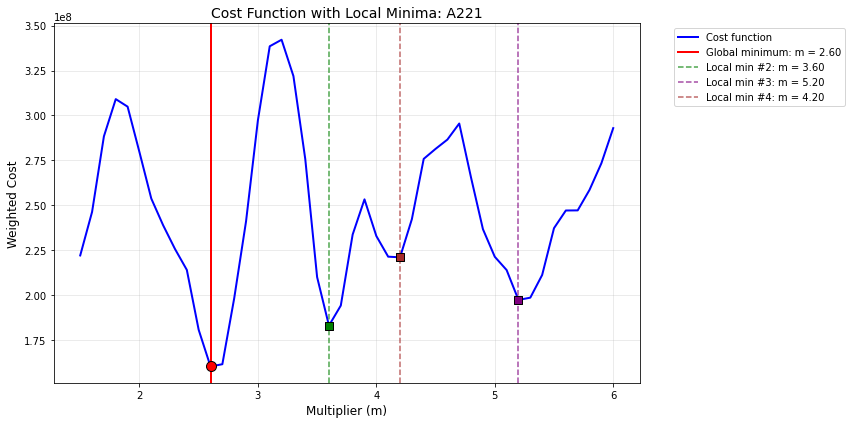


Local Minima Summary for A221:
--------------------------------------------------
#1: m = 2.60, cost = 1.60e+08 (GLOBAL)
#2: m = 3.60, cost = 1.83e+08
#3: m = 5.20, cost = 1.97e+08
#4: m = 4.20, cost = 2.21e+08


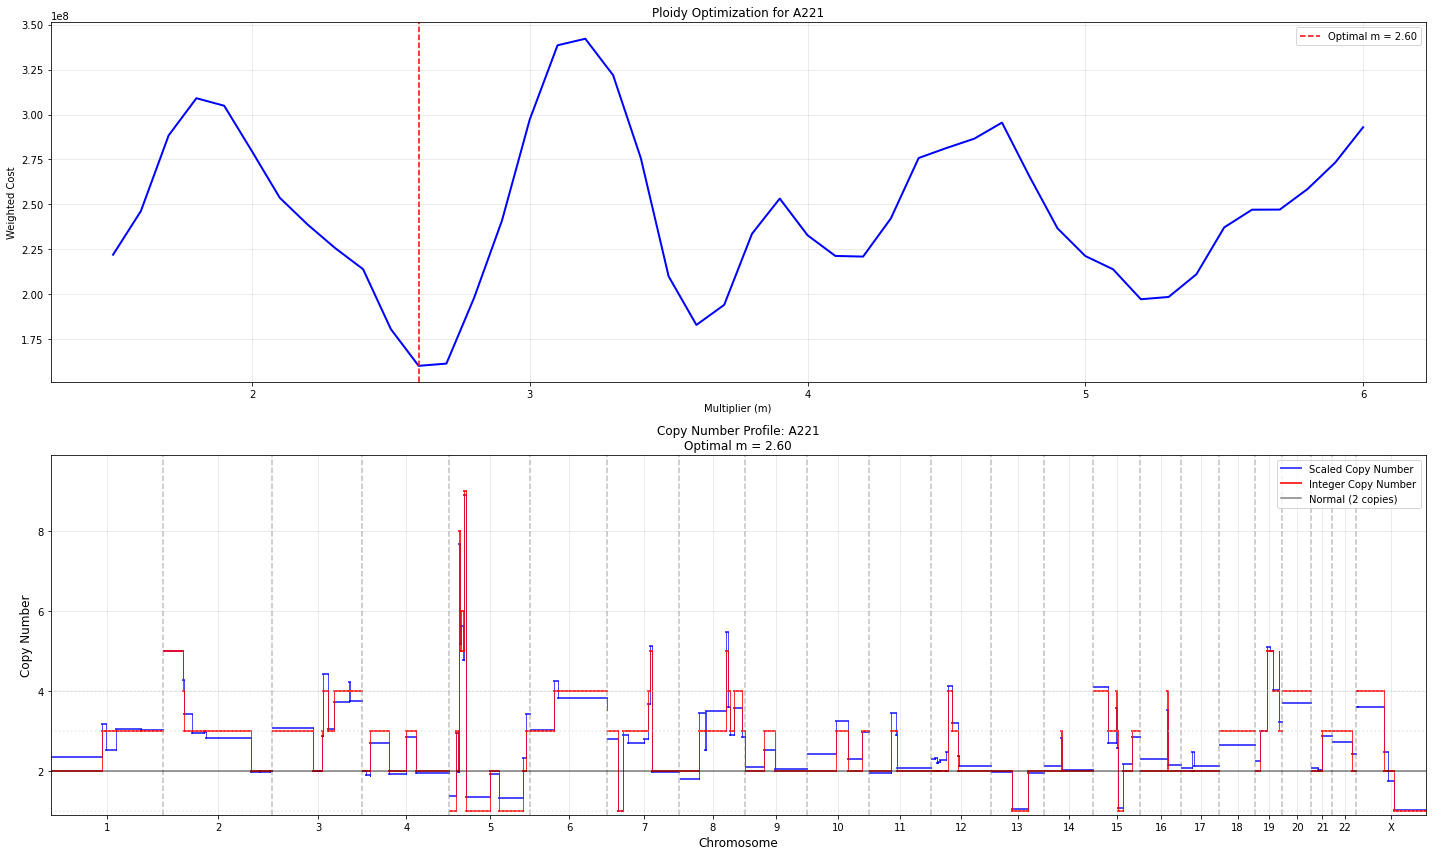

Completed plots for A221

Plotting results for population: A222


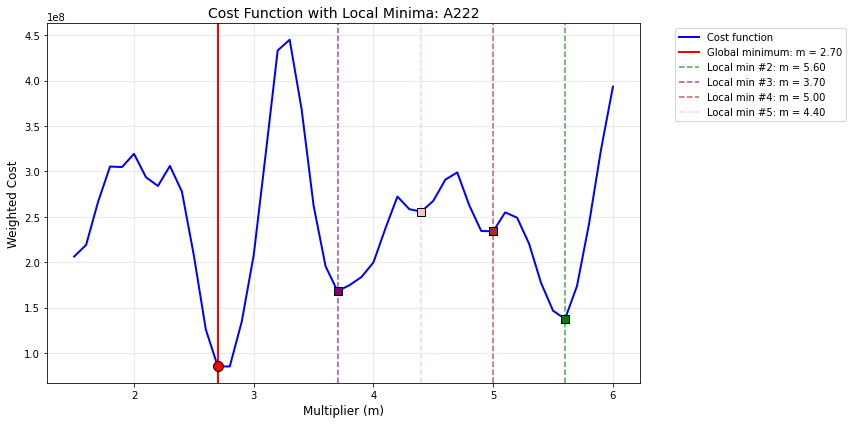


Local Minima Summary for A222:
--------------------------------------------------
#1: m = 2.70, cost = 8.51e+07 (GLOBAL)
#2: m = 5.60, cost = 1.37e+08
#3: m = 3.70, cost = 1.68e+08
#4: m = 5.00, cost = 2.34e+08
#5: m = 4.40, cost = 2.56e+08


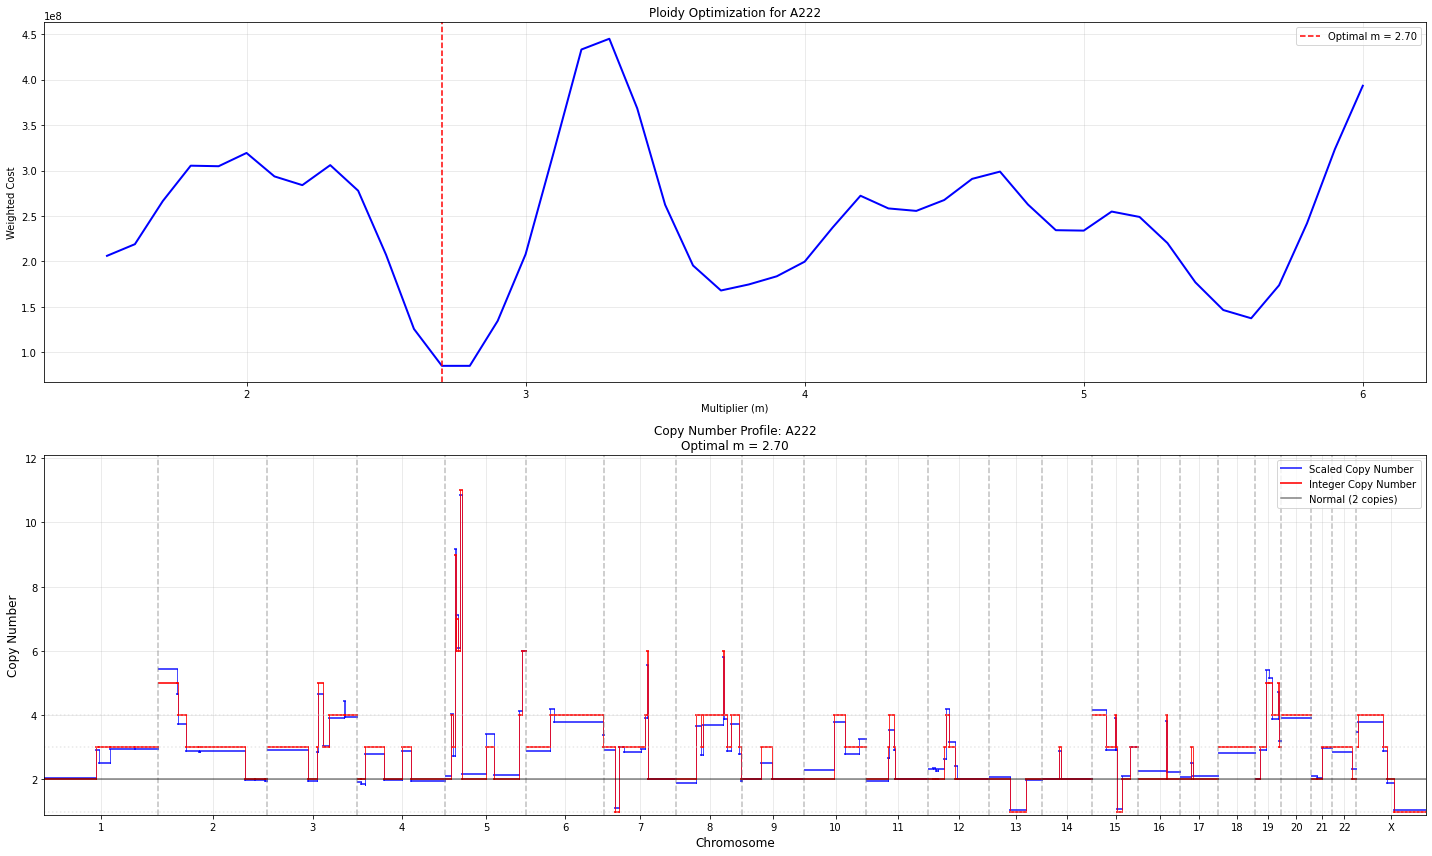

Completed plots for A222


In [32]:
# Test the plotting functions on your ploidy results
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Plotting results for population: {pop_name}")
    
    # Get the results for this population
    results = ploidy_results_A[pop_name]
    profile_df = profile_dfs_A[pop_name]
    
    # 1. Plot cost function with local minima
    plot_cost_function_with_minima(
        cost_results=results['cost_results'],
        local_minima=results['local_minima'],
        pop_name=pop_name,
        optimal_m=results['optimal_multiplier']
    )
    
    # 2. Plot the full ploidy optimization (cost function + copy number profile)
    pop_col = f"{pop_name}_ratio"  # Reconstruct the column name
    plot_ploidy_optimization(
        results_df=profile_df,
        cost_results=results['cost_results'],
        optimal_m=results['optimal_multiplier'],
        pop_col=pop_col
    )
    
    print(f"Completed plots for {pop_name}")

In [33]:
import os
import pandas as pd

# Define the parquet file path
parquet_file = f"../data/{tumor}/hap_count_df.parquet"

# Check if parquet file exists, if so load it, otherwise create and save it
if os.path.exists(parquet_file):
    print("Loading hap_count_df from parquet file...")
    hap_count_df = pd.read_parquet(parquet_file)
    print(f"Loaded hap_count_df with shape: {hap_count_df.shape}")
else:
    print("Parquet file not found. Creating hap_count_df from source data...")
    
    hap_count_df = pd.read_csv(f"/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/{tumor}/per_cell_hap_count.txt", sep = "\t")
    binning = pd.read_csv("/mnt/wigstore3/user/kendall/hg19.50mer/hg19.varbin.gc.content.2.5k.bowtie.k50.txt", sep='\t')
    bin_loc_dict = dict(zip(binning.index, binning["bin.start.abspos"]))
    chrom_dict = dict(zip(binning.index, binning["bin.chrom"]))

    hap_count_df["abspos"] = hap_count_df["bin"].apply(lambda x : bin_loc_dict[x])
    hap_count_df["chrom"] = hap_count_df["bin"].apply(lambda x : chrom_dict[x])
    hap_count_df= hap_count_df[["chrom", "abspos","bin", "cell", "hap_count","Total"]]

    print(f"Created hap_count_df with shape: {hap_count_df.shape}")
    
    # Save as parquet for future use
    print("Saving hap_count_df as parquet file...")
    hap_count_df.to_parquet(parquet_file, index=False)
    
    # Check file size
    file_size = os.path.getsize(parquet_file)
    print(f"Saved parquet file: {file_size:,} bytes ({file_size/1024**2:.2f} MB)")

print("hap_count_df ready for analysis!")

Loading hap_count_df from parquet file...
Loaded hap_count_df with shape: (8605992, 6)
hap_count_df ready for analysis!


In [34]:
hap_count_df.head()

,chrom,abspos,bin,cell,hap_count,Total
0,chr1,0,0,AATGAGGATGCAACACA,3,6
1,chr1,1925685,1,AATGAGGATGCAACACA,0,2
2,chr1,3106884,2,AATGAGGATGCAACACA,0,2
3,chr1,4351684,3,AATGAGGATGCAACACA,7,7
4,chr1,5438445,4,AATGAGGATGCAACACA,0,0


In [35]:
bin_to_chrom_dict = dict(zip(hap_count_df[["chrom", "bin"]].drop_duplicates()["bin"].values, hap_count_df[["chrom", "bin"]].drop_duplicates()["chrom"].values))

In [36]:
example = list(A_dict.keys())[1]

In [37]:
# # Example usage for A211 with global min 2.4 and local min 3.1
# plot_ploidy_comparison(
#     results_df=profile_dfs_A[example],
#     cost_results=ploidy_results_A[example]['cost_results'],
#     optimal_m=2.4,  # or use ploidy_results_A[example]['optimal_multiplier']
#     local_m=3.1,   # pick from ploidy_results_A[example]['local_minima']
#     pop_col=f'{example}_ratio'
# )

In [38]:
#Get all cells in example
example_cells = A_dict[example]['cells']
#Filter hap_count_df for these cells
example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
example_hap_ratio['hap_ratio'] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
example_hap_ratio['folded'] = example_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information    
example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])

<AxesSubplot:>

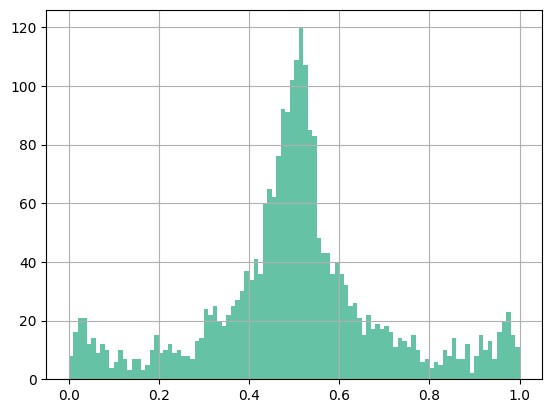

In [40]:
example_hap_ratio["hap_ratio"].hist(bins=100, range=(0,1))

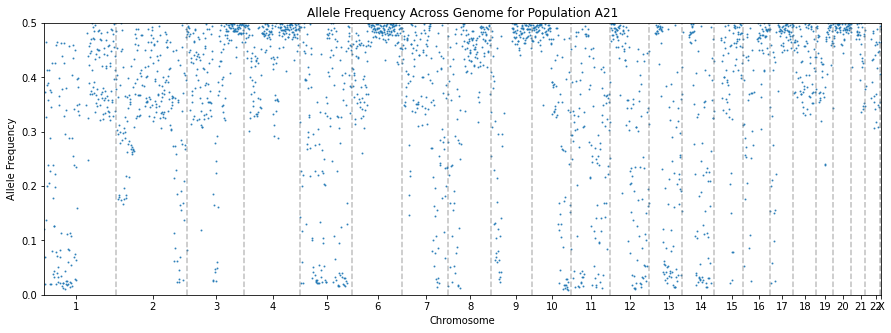

In [39]:
# plot the folded allele frequency along the genome
example_hap_ratio_sorted = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(example_hap_ratio_sorted['abspos'], example_hap_ratio_sorted['folded'], s=1, alpha=0.8)
plt.xlabel('Chromosome')
plt.ylabel('Allele Frequency')
plt.title('Allele Frequency Across Genome for Population ' + example)
# Add vertical lines for chromosome boundaries
chrom_boundaries = example_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = example_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(example_hap_ratio_sorted['abspos'].min(), example_hap_ratio_sorted['abspos'].max())
plt.show()

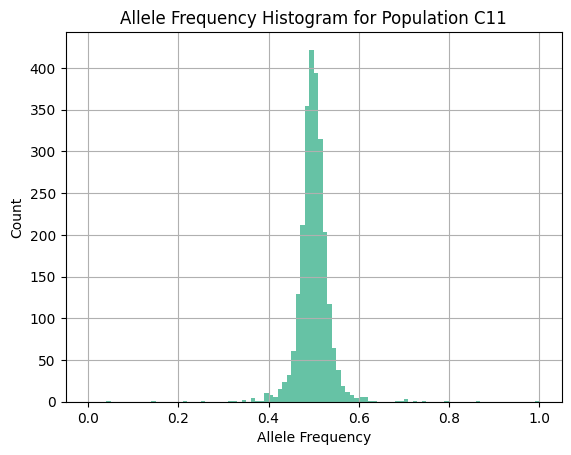

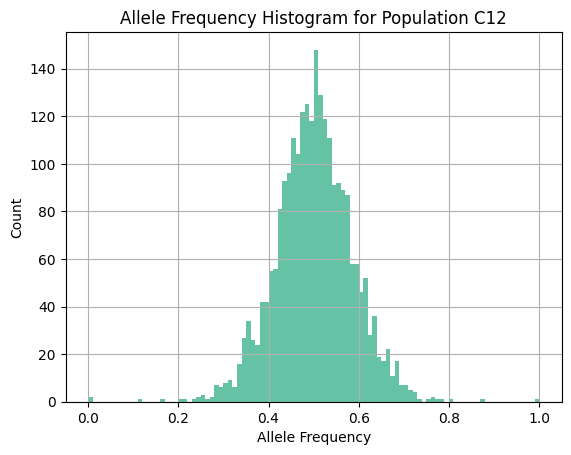

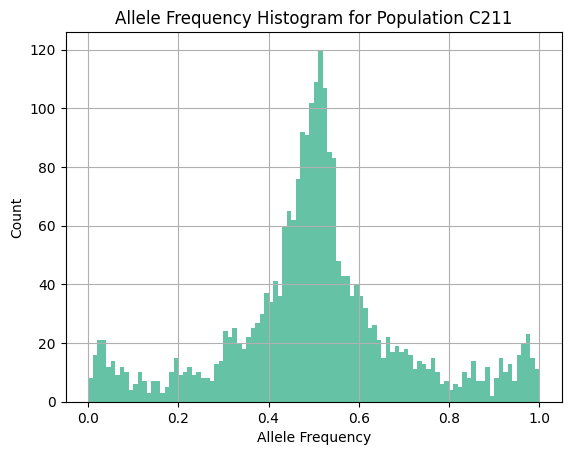

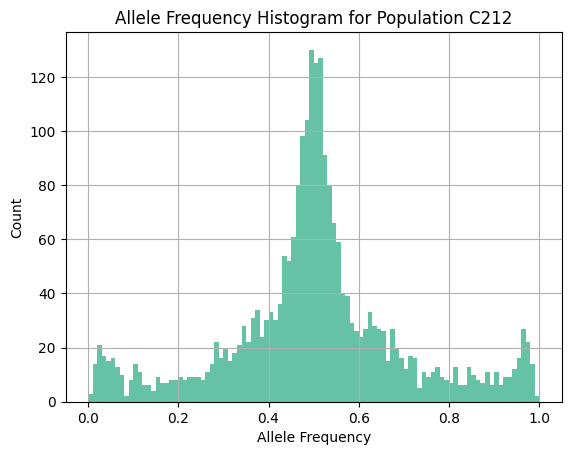

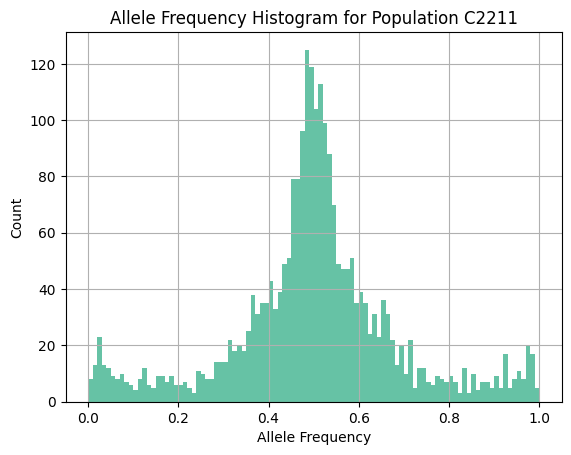

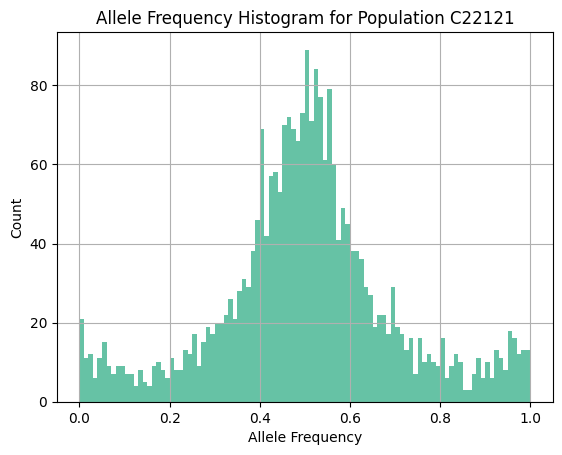

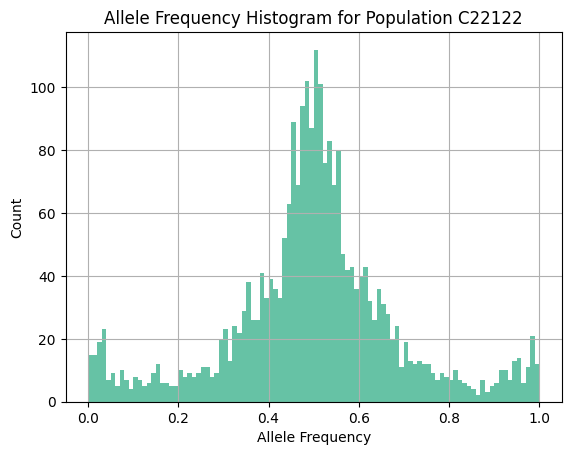

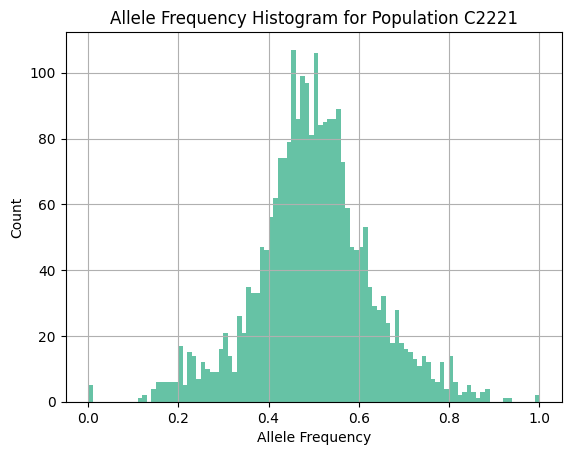

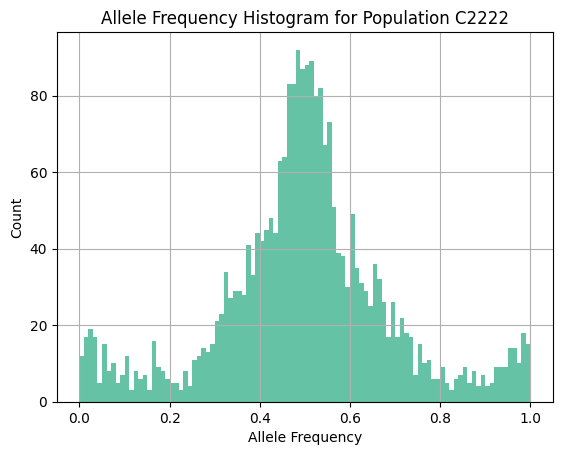

In [ ]:
hap_df_dict = {}
hap_summary_df = pd.DataFrame()
for pop_name in C_dict.keys():
    #Get all cells in example
    example_cells = C_dict[pop_name]['cells']
    #Filter hap_count_df for these cells
    example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
    # compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
    example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
    example_hap_ratio['hap_ratio_'+pop_name] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
    example_hap_ratio.rename(columns={'hap_count': 'hap_count_'+pop_name, 'Total': 'Total_'+pop_name}, inplace=True)
    example_hap_ratio['folded_'+pop_name] = example_hap_ratio['hap_ratio_'+pop_name].apply(lambda x: min(x, 1-x))
    # Add chromosome information    
    example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])
    example_hap_ratio = example_hap_ratio[["bin", "abspos", "chrom", 'hap_ratio_'+pop_name, 'folded_'+pop_name, 'hap_count_'+pop_name, 'Total_'+pop_name]]
    hap_df_dict[pop_name] = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
    example_hap_ratio['hap_ratio_'+pop_name].hist(bins=100, range=(0,1))
    plt.axvline(x=0.5, color='black', linestyle='--', label='balanced allele frequency')
    plt.axvline(x=0.33, color='blue', linestyle='--', label='1:2 allele frequency')
    plt.axvline(x=0.25, color='blue', linestyle='--')
    plt.axvline(x=0.01, color='red', linestyle='--', label='Loss of heterozygosity (LoH)')
    plt.axvline(x=0.99, color='red', linestyle='--')
    plt.legend()
    plt.title(f"Allele Frequency Histogram for Population {pop_name}")
    plt.xlabel('Allele Frequency')
    plt.ylabel('Count')
    plt.show()
    if hap_summary_df.empty:
        hap_summary_df = example_hap_ratio.sort_values(by=['chrom', 'abspos']).copy()
    else:
        hap_summary_df = hap_summary_df.merge(
            example_hap_ratio,
            on=['bin', 'abspos', 'chrom'],
            suffixes=('', f'_{pop_name}')
        )


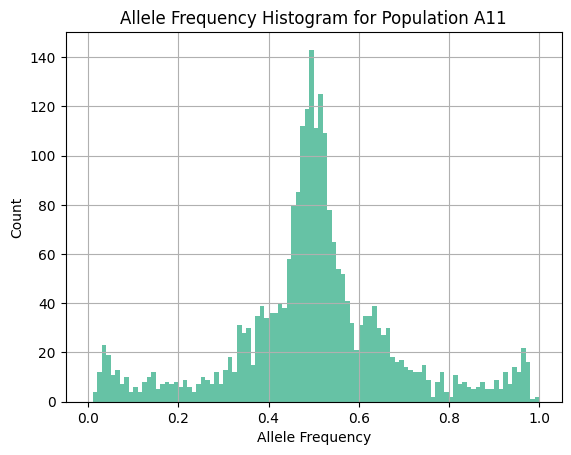

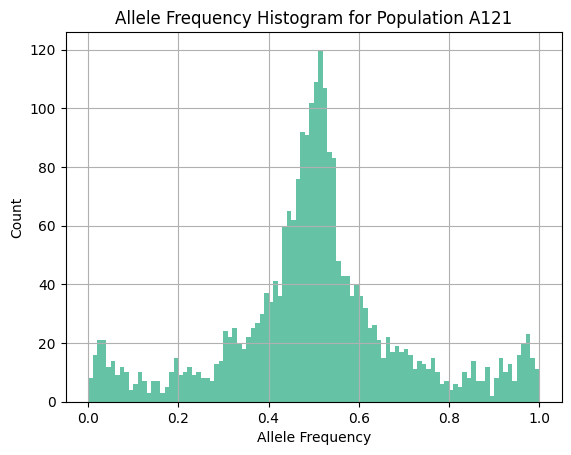

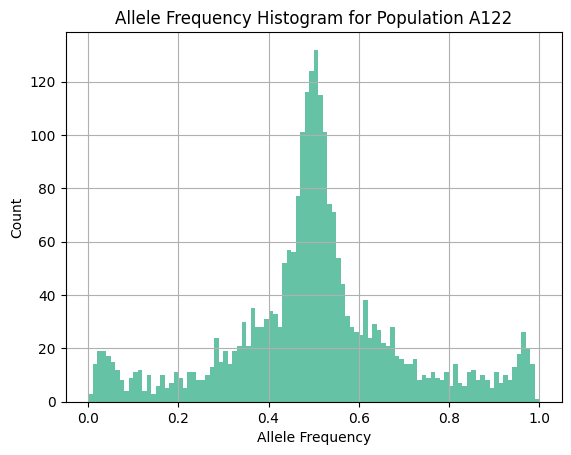

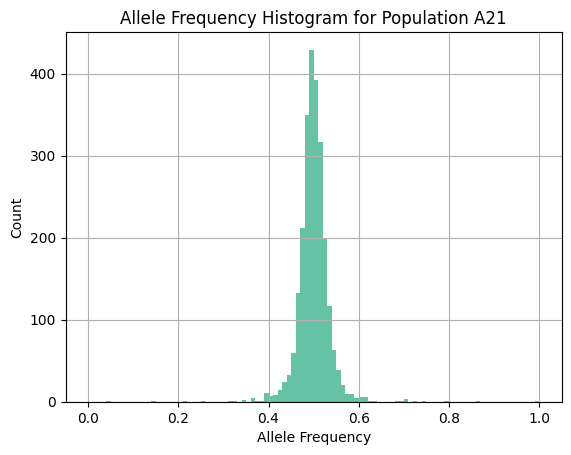

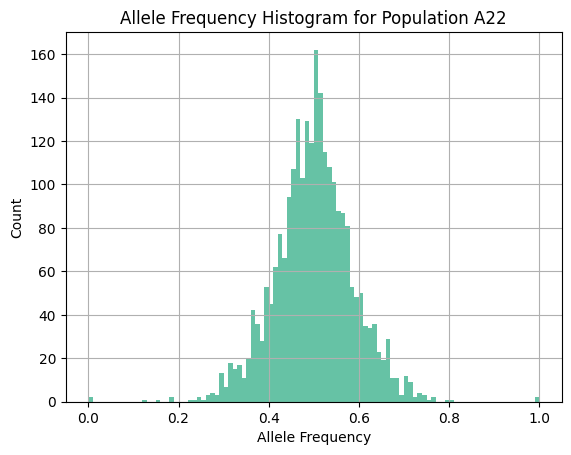

In [41]:
hap_df_dict = {}
hap_summary_df = pd.DataFrame()
for pop_name in A_dict.keys():
    #Get all cells in example
    example_cells = A_dict[pop_name]['cells']
    #Filter hap_count_df for these cells
    example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
    # compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
    example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
    example_hap_ratio['hap_ratio_'+pop_name] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
    example_hap_ratio.rename(columns={'hap_count': 'hap_count_'+pop_name, 'Total': 'Total_'+pop_name}, inplace=True)
    example_hap_ratio['folded_'+pop_name] = example_hap_ratio['hap_ratio_'+pop_name].apply(lambda x: min(x, 1-x))
    # Add chromosome information    
    example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])
    example_hap_ratio = example_hap_ratio[["bin", "abspos", "chrom", 'hap_ratio_'+pop_name, 'folded_'+pop_name, 'hap_count_'+pop_name, 'Total_'+pop_name]]
    hap_df_dict[pop_name] = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
    example_hap_ratio['hap_ratio_'+pop_name].hist(bins=100, range=(0,1))
    plt.title(f"Allele Frequency Histogram for Population {pop_name}")
    plt.xlabel('Allele Frequency')
    plt.ylabel('Count')
    plt.show()
    if hap_summary_df.empty:
        hap_summary_df = example_hap_ratio.sort_values(by=['chrom', 'abspos']).copy()
    else:
        hap_summary_df = hap_summary_df.merge(
            example_hap_ratio,
            on=['bin', 'abspos', 'chrom'],
            suffixes=('', f'_{pop_name}')
        )


In [41]:
hap_summary_df

,bin,abspos,chrom,hap_ratio_A1,folded_A1,hap_count_A1,Total_A1,hap_ratio_A21,folded_A21,hap_count_A21,Total_A21,hap_ratio_A221,folded_A221,hap_count_A221,Total_A221,hap_ratio_A222,folded_A222,hap_count_A222,Total_A222
0,0,0,chr1,0.522922,0.477078,673,1287,0.879408,0.120592,2319,2637,0.873646,0.126354,1452,1662,0.857218,0.142782,1633,1905
1,1,1925685,chr1,0.505004,0.494996,656,1299,0.373756,0.373756,1014,2713,0.382784,0.382784,627,1638,0.358201,0.358201,677,1890
2,2,3106884,chr1,0.502250,0.497750,893,1778,0.069848,0.069848,243,3479,0.073083,0.073083,142,1943,0.060755,0.060755,148,2436
3,3,4351684,chr1,0.502664,0.497336,1132,2252,0.019043,0.019043,82,4306,0.032258,0.032258,78,2418,0.028076,0.028076,81,2885
4,4,5438445,chr1,0.536641,0.463359,703,1310,0.535650,0.464350,1495,2791,0.516213,0.483787,796,1542,0.495707,0.495707,866,1747
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2356,1413,1676815651,chr9,0.470348,0.470348,920,1956,0.495441,0.495441,1304,2632,0.479748,0.479748,912,1901,0.495363,0.495363,1282,2588
2357,1414,1677912808,chr9,0.517615,0.482385,573,1107,0.454718,0.454718,718,1579,0.473729,0.473729,559,1180,0.505003,0.494997,757,1499
2358,1415,1679086331,chr9,0.499133,0.499133,576,1154,0.531569,0.468431,884,1663,0.515099,0.484901,597,1159,0.484081,0.484081,745,1539
2359,2359,2881033286,chrX,0.510667,0.489333,1125,2203,0.510871,0.489129,3266,6393,0.526328,0.473672,2189,4159,0.505388,0.494612,2720,5382


In [42]:
hap_summary_df.to_csv(f"../data/{tumor}/{tumor}_haplotype_summary_by_population_A.txt", sep="\t", index=False)

In [43]:
normal_A

'A1'

In [44]:
#Get all cells in A1
normal_cells = A_dict[normal_A]['cells']
#Filter hap_count_df for these cells
normal_hap_df = hap_count_df[hap_count_df['cell'].isin(normal_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
normal_hap_ratio = normal_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
normal_hap_ratio['hap_ratio'] = normal_hap_ratio['hap_count'] / normal_hap_ratio['Total']
normal_hap_ratio['folded'] = normal_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information
normal_hap_ratio["chrom"] = normal_hap_ratio["bin"].apply(lambda x: bin_to_chrom_dict[x])

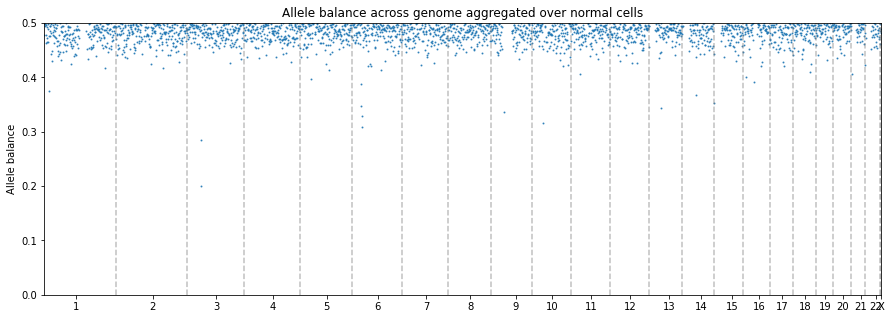

In [45]:
# plot the folded allele frequency along the genome
normal_hap_ratio_sorted = normal_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(normal_hap_ratio_sorted['abspos'], normal_hap_ratio_sorted['folded'], s=1, alpha=0.8)
#plt.xlabel('Chromosome')
plt.ylabel('Allele balance')
plt.title('Allele balance across genome aggregated over normal cells')
# Add vertical lines for chromosome boundaries
chrom_boundaries = normal_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = normal_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(normal_hap_ratio_sorted['abspos'].min(), normal_hap_ratio_sorted['abspos'].max())
plt.show()

In [46]:
A_df.head()

,cell,population,normal_population
0,AAAACCAAAGTAGTTCT,A1,True
1,AAAACCAACAAGACAAT,A1,True
2,AAAACCTTGACTTAATG,A1,True
3,AAAATGAAATCCTCAGA,A1,True
4,AAAATGATCCGGAGAAG,A1,True


In [47]:
#Get all tumor cells in (not A1)
tumor_cells = A_df[A_df['population'] != normal_A]['cell'].tolist()
#Filter hap_count_df for these cells
tumor_hap_df = hap_count_df[hap_count_df['cell'].isin(tumor_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
tumor_hap_ratio = tumor_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
tumor_hap_ratio['hap_ratio'] = tumor_hap_ratio['hap_count'] / tumor_hap_ratio['Total']
tumor_hap_ratio['folded'] = tumor_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information
tumor_hap_ratio["chrom"] = tumor_hap_ratio["bin"].apply(lambda x: bin_to_chrom_dict[x])


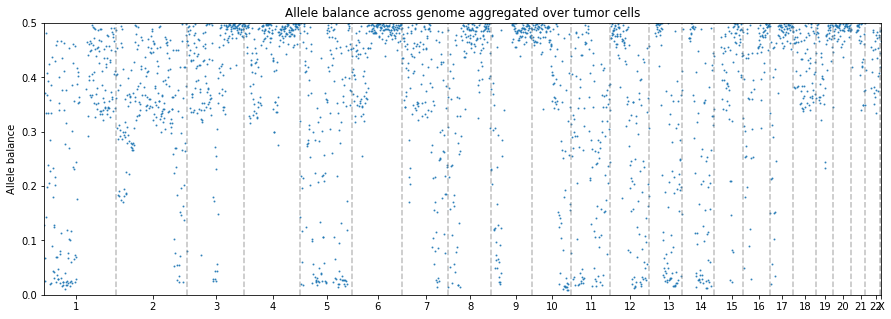

In [48]:
# plot the folded allele frequency along the genome
tumor_hap_ratio_sorted = tumor_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(tumor_hap_ratio_sorted['abspos'], tumor_hap_ratio_sorted['folded'], s=1, alpha=0.8)
#plt.xlabel('Chromosome')
plt.ylabel('Allele balance')
plt.title('Allele balance across genome aggregated over tumor cells')
# Add vertical lines for chromosome boundaries
chrom_boundaries = tumor_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = tumor_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(tumor_hap_ratio_sorted['abspos'].min(), tumor_hap_ratio_sorted['abspos'].max())
plt.show()

In [49]:
# # Example usage for example with global min 2.4 and local min 3.1
# plot_ploidy_comparison(
#     results_df=profile_dfs_A[example],
#     cost_results=ploidy_results_A[example]['cost_results'],
#     optimal_m=2.4,
#     local_m=3.1,
#     pop_col=example + '_ratio',
#     hap_count_df=hap_count_df,
#     cells=A_dict[example]['cells']
# )


Creating ploidy comparison for population: A21


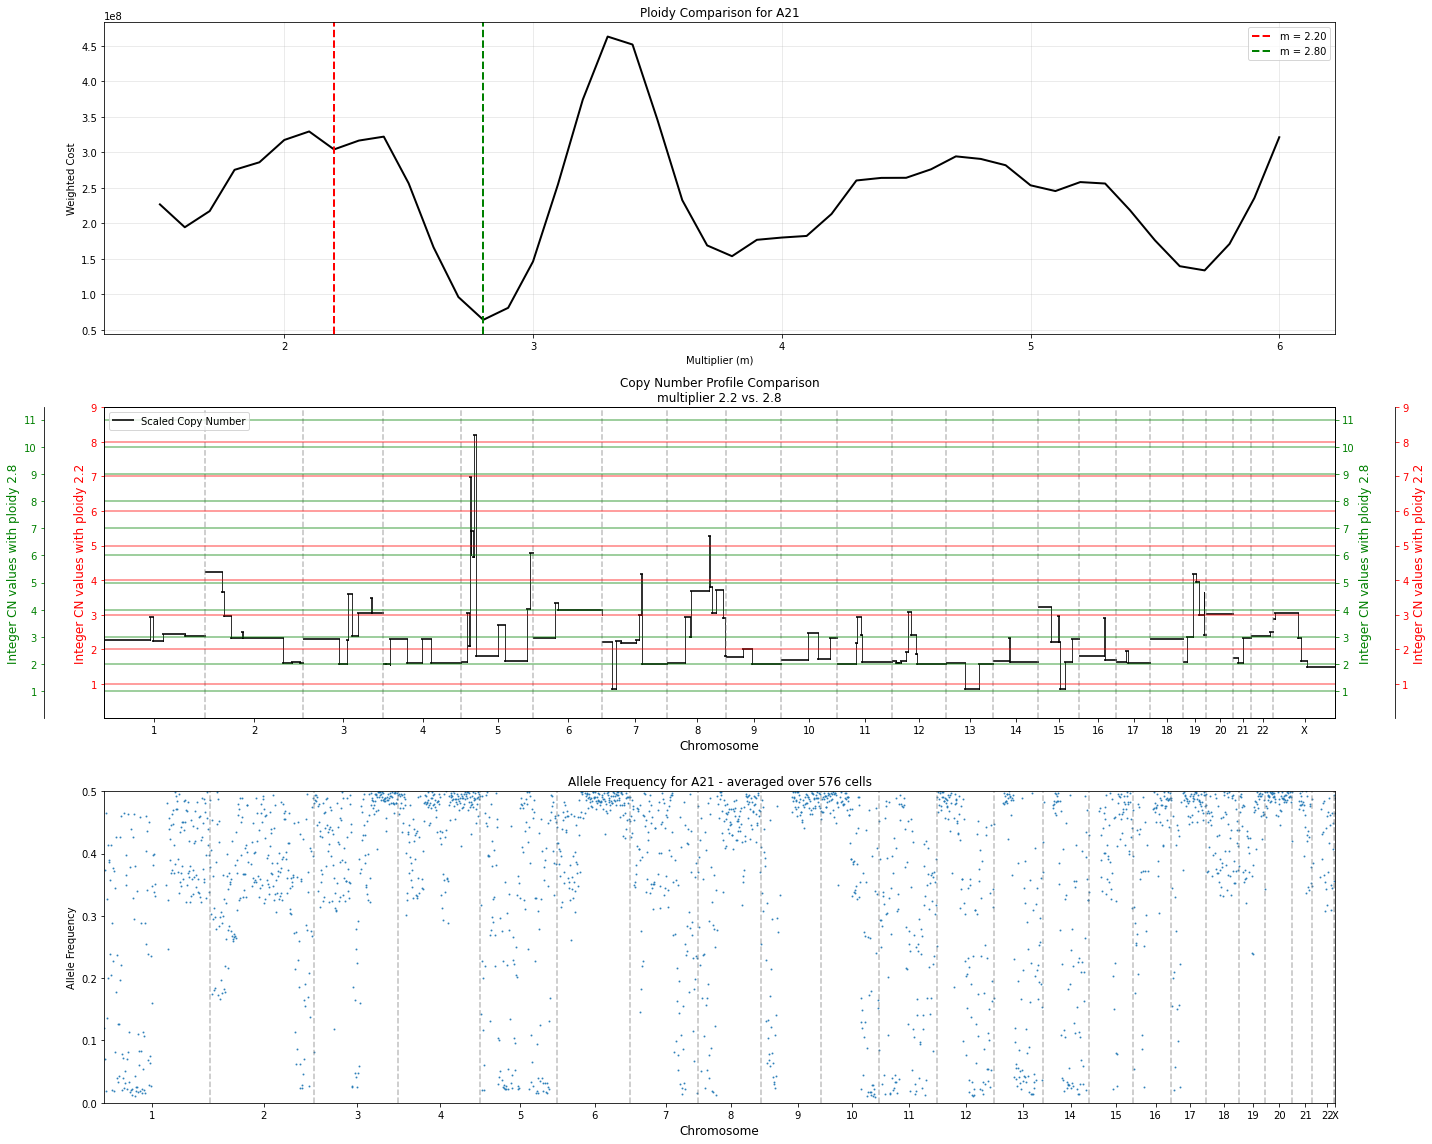

Compared 2.20 vs 2.80 for A21

Creating ploidy comparison for population: A221


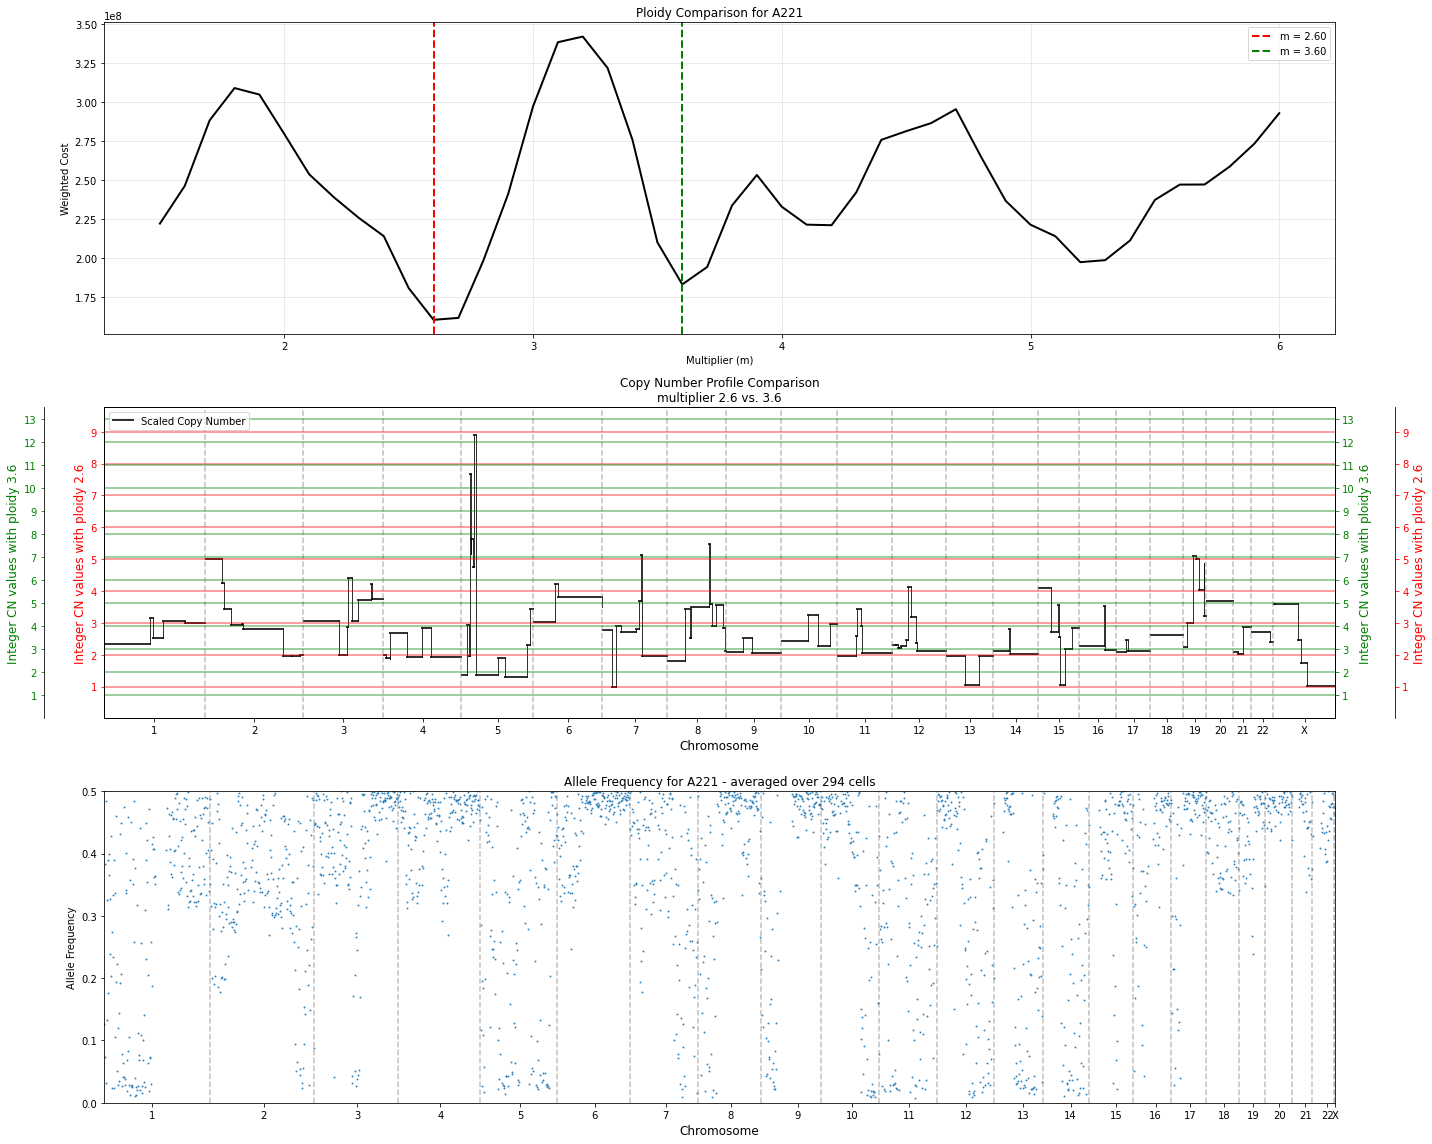

Compared 2.60 vs 3.60 for A221

Creating ploidy comparison for population: A222


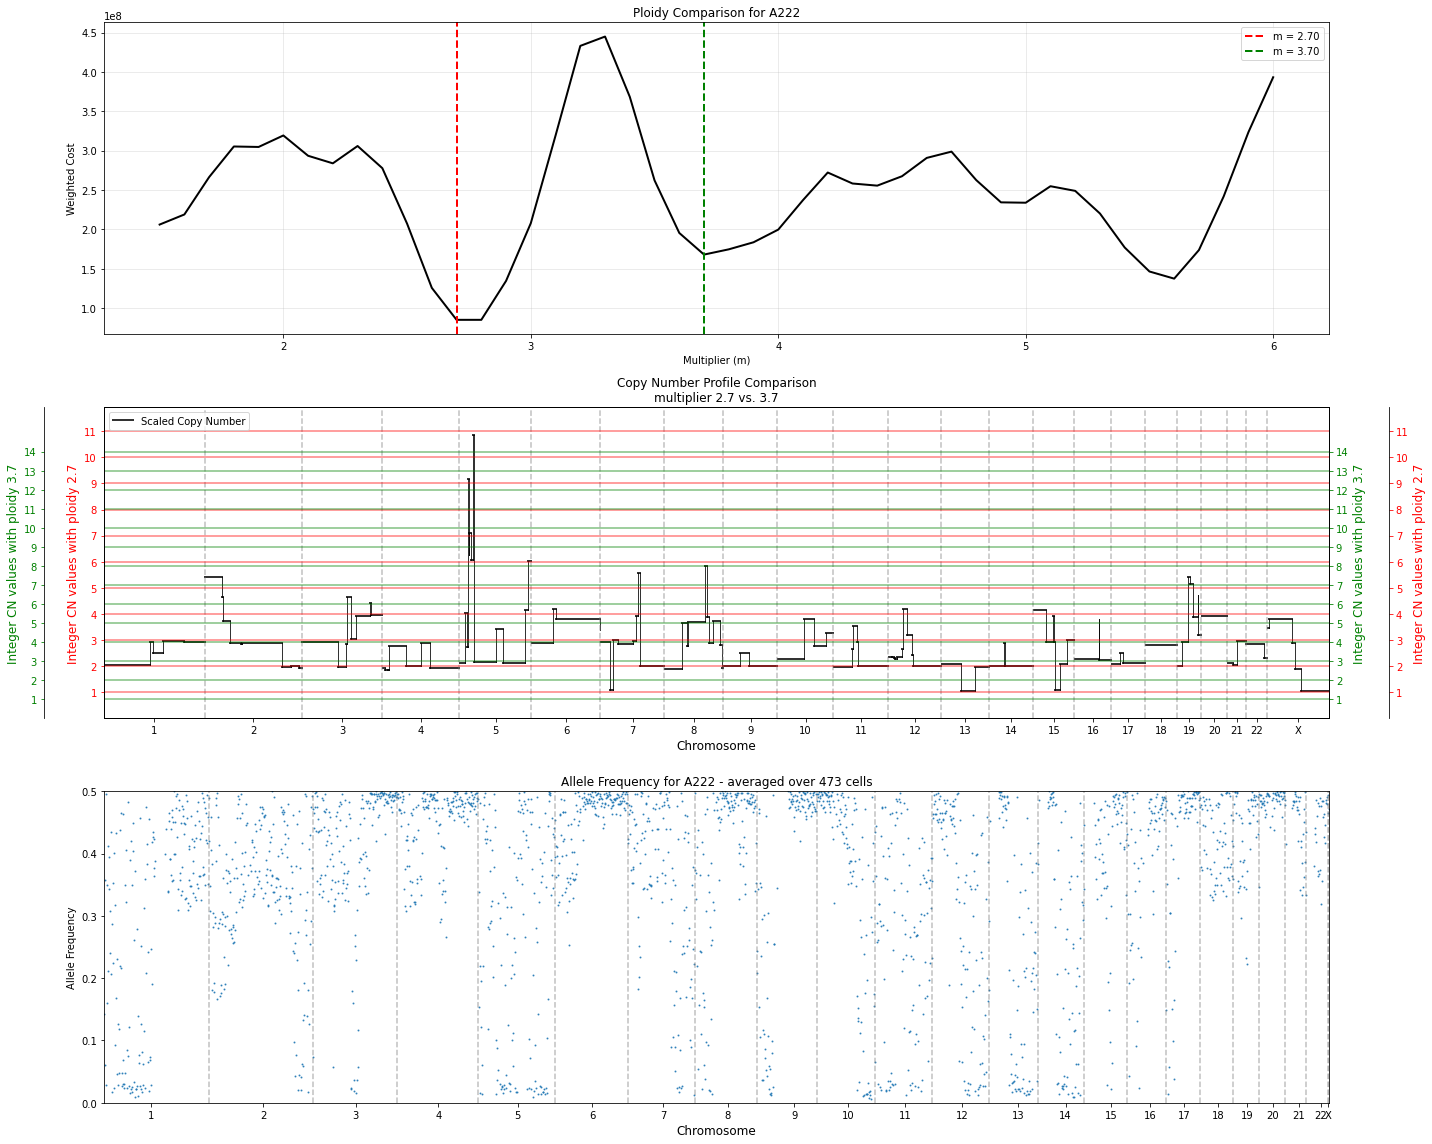

Compared 2.70 vs 3.70 for A222


In [50]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to ploidy 2 (that's not the global minimum)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Pick the one closest to 2.0
        second_best_m = min(other_minima, key=lambda x: abs(x - 2.0))
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")


Creating ploidy comparison for population: A21


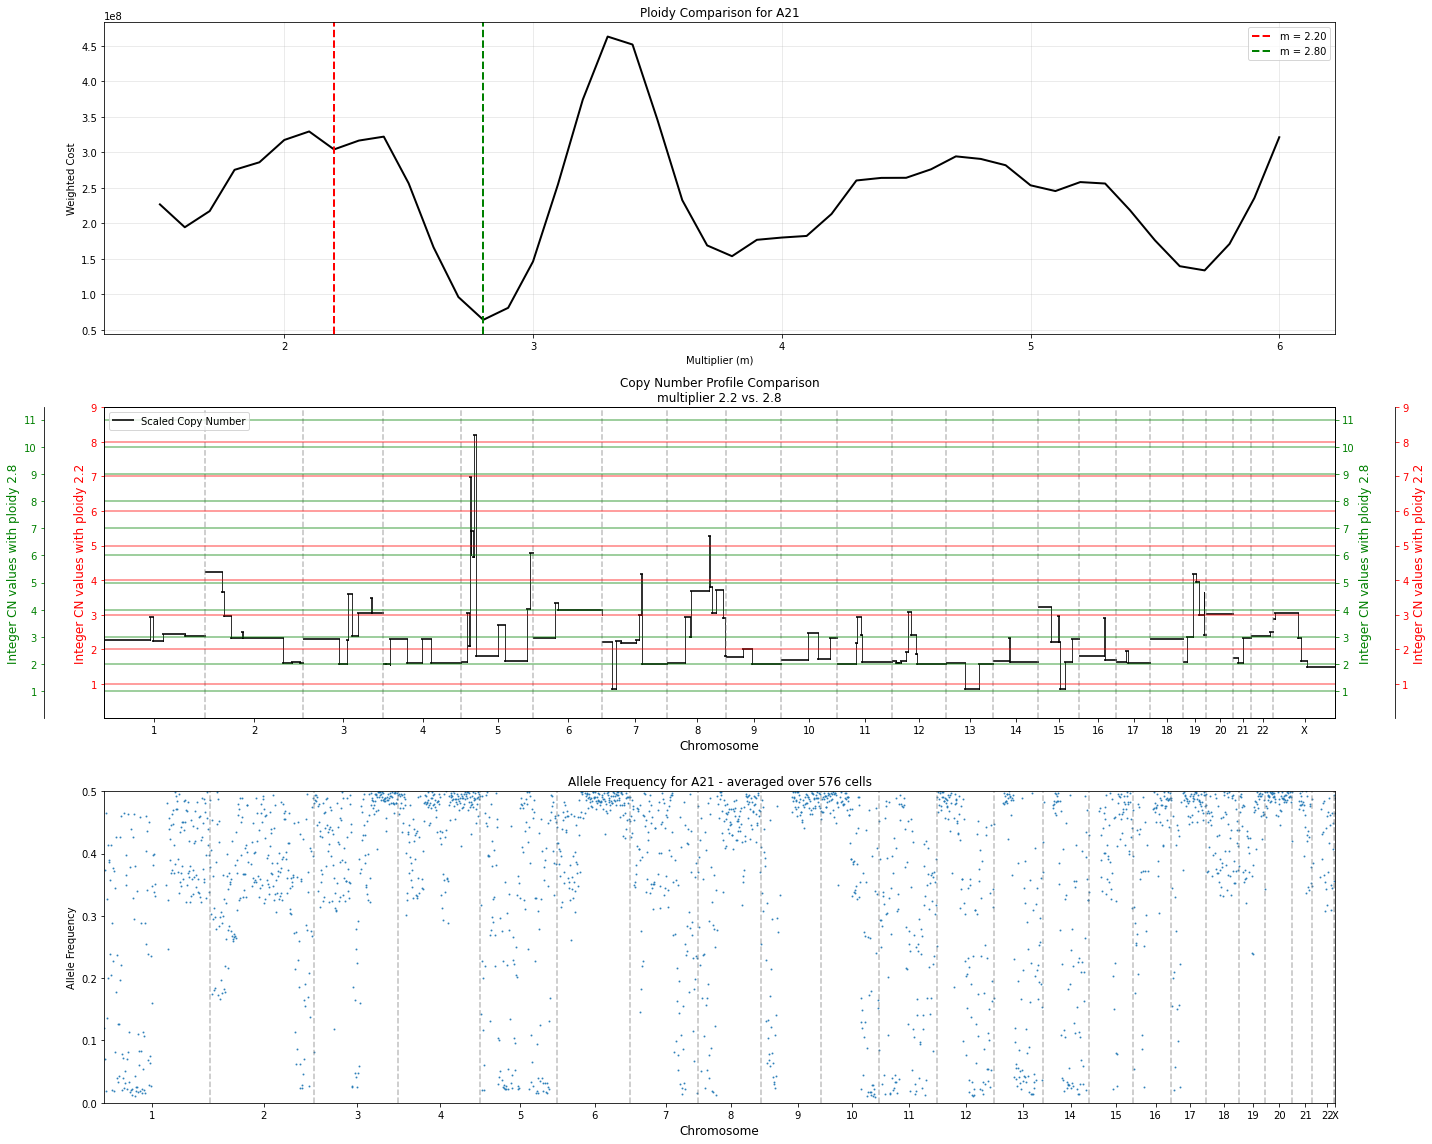

Compared 2.20 vs 2.80 for A21

Creating ploidy comparison for population: A221


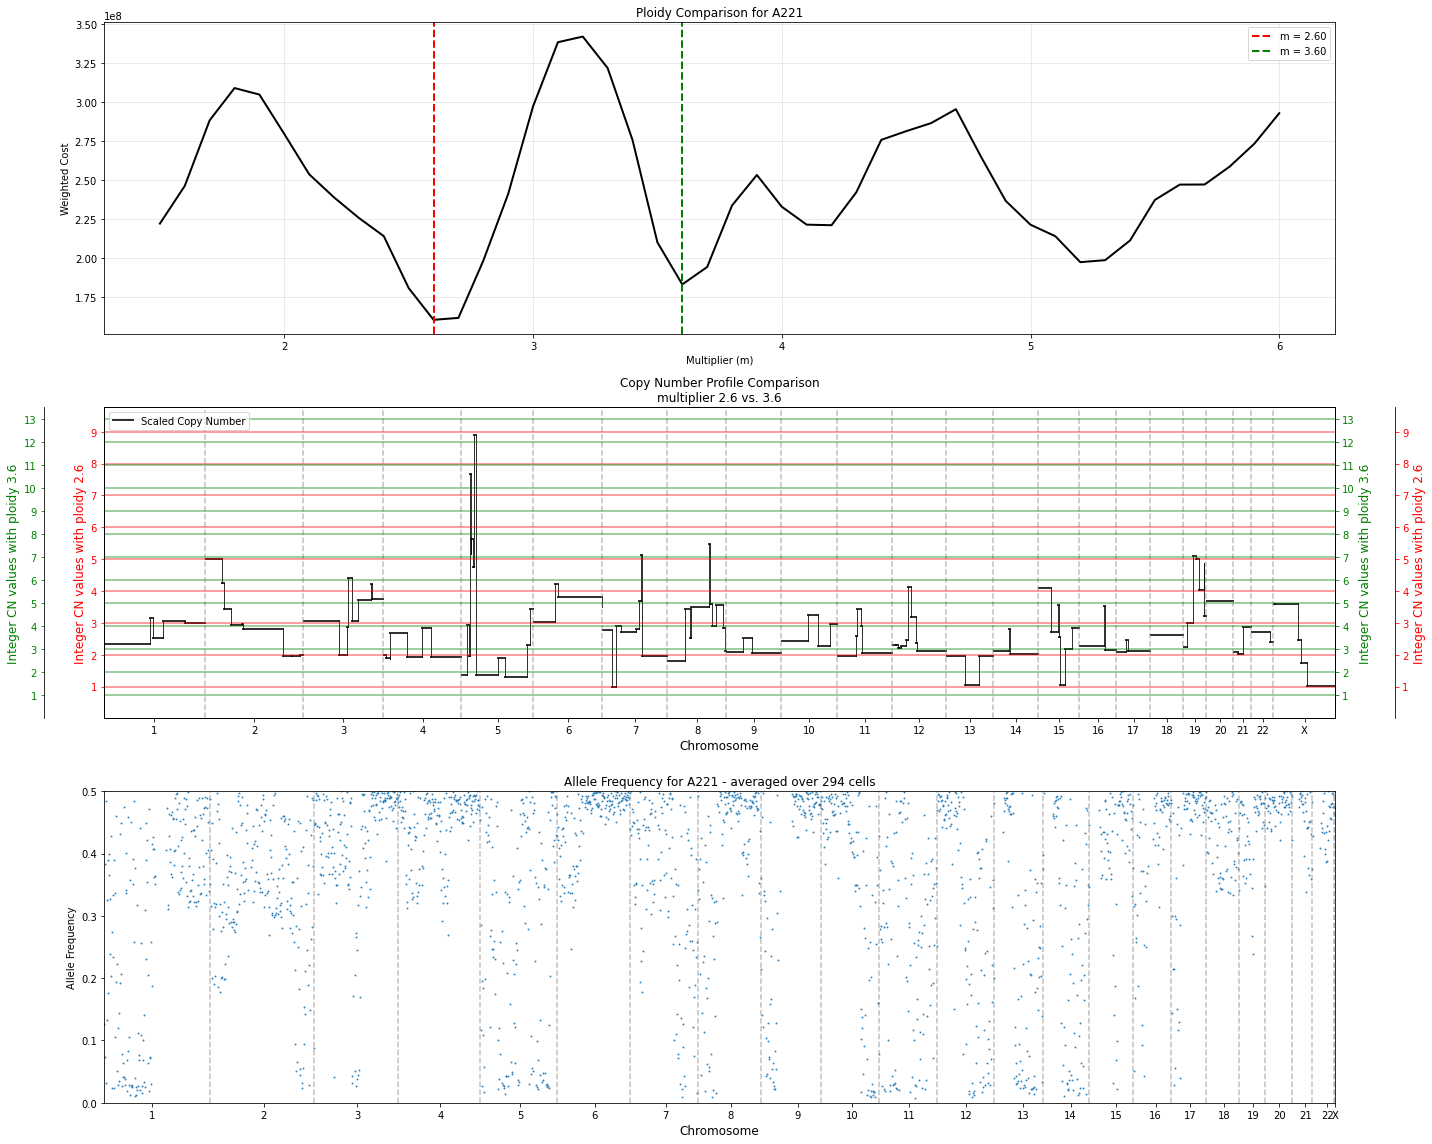

Compared 2.60 vs 3.60 for A221

Creating ploidy comparison for population: A222


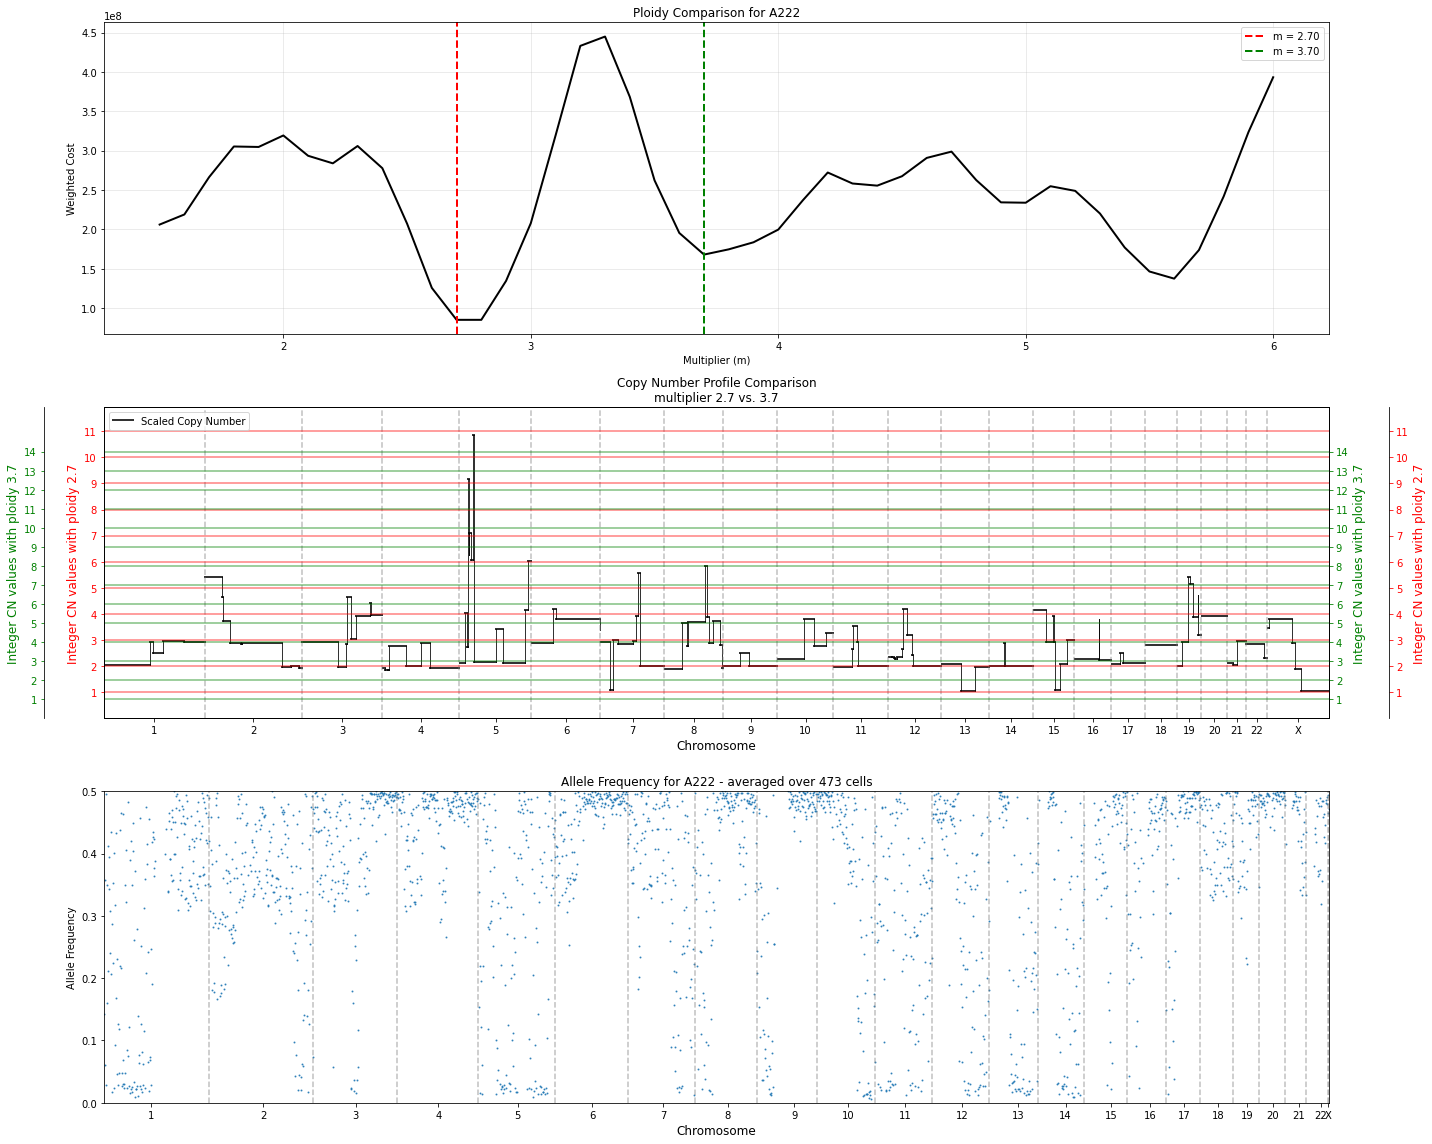

Compared 2.70 vs 3.70 for A222


In [51]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - optimal_m) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - optimal_m) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")

In [52]:
# # reorder A_dict based on new order from overlap_df index
# A_dict_reordered = {k: A_dict[k] for k in overlap_df.index}

In [53]:
# Add to your imports at the top:



In [54]:
# Create population summary table
summary_rows = []

for pop_name in A_dict.keys():
    # Get cells for this population
    pop_cells = A_dict[pop_name]['cells']
    num_cells = len(pop_cells)
    
        

    # Calculate average read count per cell for this population
    pop_data = all_data[pop_cells]
    avg_read_count = pop_data.sum().sum() / num_cells
    
    # Get relative counts (already computed in relative_counts_A)
    relative_count = relative_counts_A[pop_name].mean()

    if pop_name!= normal_A:
        results = ploidy_results_A[pop_name]
        local_minima = results['local_minima']
        target_m = 2 * relative_count
        #pick two best minima
        optimal_m = results['optimal_multiplier']
    
        # Find the local minimum closest to the global minimum (excluding the global minimum itself)
        other_minima = [m for m, _ in local_minima if m != optimal_m]
        
        if other_minima:
            # Find the minimum distance to the global minimum
            min_distance = min(abs(m - optimal_m) for m in other_minima)
            # Get all minima at this minimum distance
            closest_minima = [m for m in other_minima if abs(m - optimal_m) == min_distance]
            # Pick the smaller one if there are ties
            second_best_m = min(closest_minima)
    # Get relative ploidy from ploidy_results_A (if it exists, otherwise it's the normal so use 1.0)
    if pop_name in ploidy_results_A:
        relative_ploidy = optimal_m
    else:
        relative_ploidy = 2.0  # Normal population
        second_best_m = 2.0
    
    # Add (normal) label if this is the normal population
    display_name = f"{pop_name} (normal)" if pop_name == normal_A else pop_name
    
    summary_rows.append({
        'pop_name': display_name,
        'num_cells': num_cells,
        'avg_read_count_per_cell': avg_read_count,
        'relative_counts': relative_count,
        'best_ploidy': relative_ploidy,
        'second_best' : second_best_m
    })

# Create DataFrame
population_summary_table = pd.DataFrame(summary_rows)

population_summary_table["rel_counts*2"] = population_summary_table["relative_counts"] * 2
#display it nicely
population_summary_table

,pop_name,num_cells,avg_read_count_per_cell,relative_counts,best_ploidy,second_best,rel_counts*2
0,A1 (normal),284,67580.362676,1.000000,2.0,2.0,2.000000
1,A21,576,71108.725694,1.052210,2.2,2.8,2.104420
2,A221,294,85844.850340,1.270263,2.6,3.6,2.540526
3,A222,473,79372.936575,1.174497,2.7,3.7,2.348994


In [55]:
population_summary_table.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_A.txt", sep="\t", index=False)

=== Creating Copy Number Heatmaps ===
Processing 124 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Heatmap A matrix dimensions: 124 segments × 1627 cells
Expanding heatmap from 124 segments to 5256 rows...

Chromosome representation in heatmap:
chr1: 438 rows, 245,459,747 bp total
chr2: 421 rows, 234,695,583 bp total
chr3: 346 rows, 193,355,005 bp total
chr4: 334 rows, 187,016,981 bp total
chr5: 311 rows, 173,502,285 bp total
chr6: 295 rows, 165,412,919 bp total
chr7: 276 rows, 154,658,822 bp total
chr8: 252 rows, 140,707,474 bp total
chr9: 234 rows, 131,151,738 bp total
chr10: 238 rows, 133,218,101 bp total
chr11: 236 rows, 132,149,408 bp total
chr12: 228 rows, 127,978,359 bp total
chr13: 202 rows, 113,350,205 bp total
chr14: 189 rows, 105,554,000 bp total
chr15: 176 rows, 98,373,534 bp total
chr16: 158 rows, 88,486,226 bp total
chr17: 142

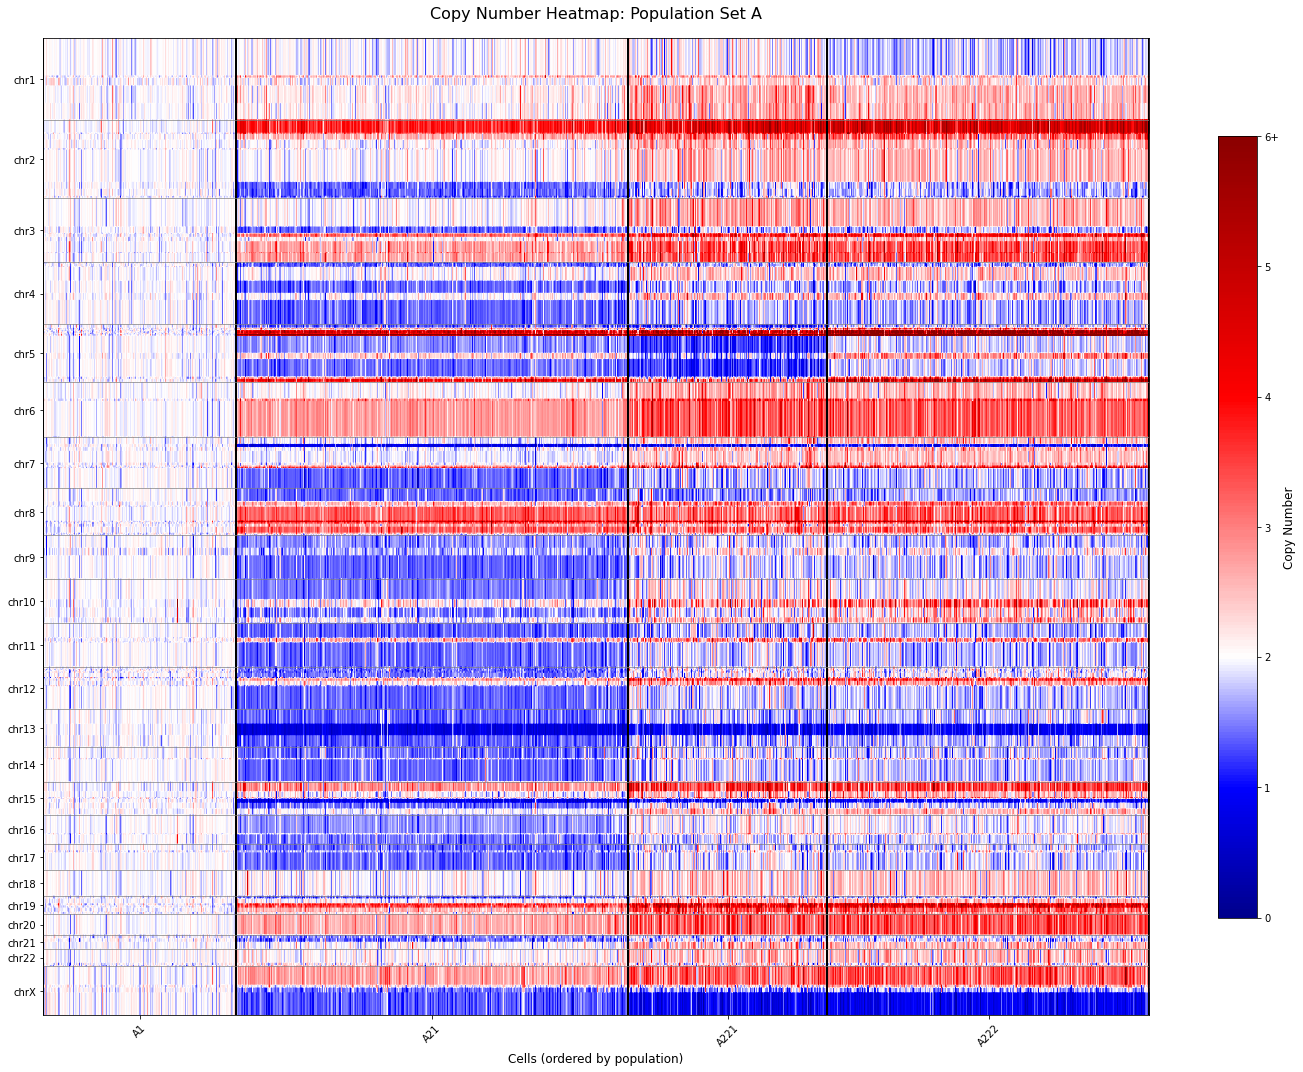

In [56]:
from copy_number import create_copy_number_matrix_fast
from visualization import plot_copy_number_heatmap, plot_overlap_matrix_figure

# Then you can use these functions in your analysis:

# Create heatmaps for both population sets
print("=== Creating Copy Number Heatmaps ===")

# For Population Set A
heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
    all_data, 
    A_dict, 
    ratios_A, 
    {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
    normal_A
)

print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)

In [57]:
# Get all population ratio columns (excluding normal population) for B
pop_ratio_cols_B = [col for col in ratios_B.columns if col.endswith('_ratio') and col != f"{normal_B}_ratio"]

ploidy_results_B = {}
profile_dfs_B = {}

print(f"Normal population: {normal_B}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_B]}")

for pop_col in pop_ratio_cols_B:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")

    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_B,
        relative_counts_B,
        pop_col,
        m_range=[1.5, 6],
        step_size=0.1,
        find_local_minima=True,
        window_size=2
    )

    ploidy_results_B[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima
    }
    profile_dfs_B[pop_name] = results_df

    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")

Normal population: B1
Populations to optimize: ['B21', 'B22']

Optimizing ploidy for population: B21
Target multiplier based on relative counts: 2.11

Optimal Results for B21:
Optimal multiplier (m): 2.200
Minimum cost: 2.99e+08
Average copy number: 2.24
Found 5 local minima
Optimal multiplier for B21: 2.200
Found 5 local minima: ['2.80', '5.70', '3.80', '5.10', '2.20']

Optimizing ploidy for population: B22
Target multiplier based on relative counts: 2.44

Optimal Results for B22:
Optimal multiplier (m): 2.700
Minimum cost: 1.03e+08
Average copy number: 2.71
Found 6 local minima
Optimal multiplier for B22: 2.700
Found 6 local minima: ['2.70', '5.50', '3.70', '5.00', '4.20']


In [58]:
# Get all population ratio columns (excluding normal population) for C
pop_ratio_cols_C = [col for col in ratios_C.columns if col.endswith('_ratio') and col != f"{normal_C}_ratio"]

ploidy_results_C = {}
profile_dfs_C = {}

print(f"Normal population: {normal_C}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_C]}")

for pop_col in pop_ratio_cols_C:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")

    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_C,
        relative_counts_C,
        pop_col,
        m_range=[1.5, 6],
        step_size=0.1,
        find_local_minima=True,
        window_size=2
    )

    ploidy_results_C[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima
    }
    profile_dfs_C[pop_name] = results_df

    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")

Normal population: C1
Populations to optimize: ['C211', 'C212', 'C22']

Optimizing ploidy for population: C211
Target multiplier based on relative counts: 2.39

Optimal Results for C211:
Optimal multiplier (m): 2.700
Minimum cost: 8.55e+07
Average copy number: 2.72
Found 5 local minima
Optimal multiplier for C211: 2.700
Found 5 local minima: ['2.70', '5.60', '3.70', '4.90', '4.40']

Optimizing ploidy for population: C212
Target multiplier based on relative counts: 2.48

Optimal Results for C212:
Optimal multiplier (m): 2.600
Minimum cost: 1.56e+08
Average copy number: 2.59
Found 5 local minima
Optimal multiplier for C212: 2.600
Found 5 local minima: ['2.60', '3.60', '5.20', '4.20', '5.70']

Optimizing ploidy for population: C22
Target multiplier based on relative counts: 2.10

Optimal Results for C22:
Optimal multiplier (m): 2.200
Minimum cost: 3.04e+08
Average copy number: 2.24
Found 5 local minima
Optimal multiplier for C22: 2.200
Found 5 local minima: ['2.80', '5.70', '3.80', '5.10'

In [59]:
# Get all population ratio columns (excluding normal population) for D
pop_ratio_cols_D = [col for col in ratios_D.columns if col.endswith('_ratio') and col != f"{normal_D}_ratio"]

ploidy_results_D = {}
profile_dfs_D = {}

print(f"Normal population: {normal_D}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_D]}")

for pop_col in pop_ratio_cols_D:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")

    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_D,
        relative_counts_D,
        pop_col,
        m_range=[1.5, 6],
        step_size=0.1,
        find_local_minima=True,
        window_size=2
    )

    ploidy_results_D[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima
    }
    profile_dfs_D[pop_name] = results_df

    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")

Normal population: D2
Populations to optimize: ['D11', 'D12']

Optimizing ploidy for population: D11
Target multiplier based on relative counts: 2.10

Optimal Results for D11:
Optimal multiplier (m): 2.200
Minimum cost: 2.99e+08
Average copy number: 2.24
Found 5 local minima
Optimal multiplier for D11: 2.200
Found 5 local minima: ['2.80', '5.70', '3.80', '5.10', '2.20']

Optimizing ploidy for population: D12
Target multiplier based on relative counts: 2.45

Optimal Results for D12:
Optimal multiplier (m): 2.700
Minimum cost: 1.03e+08
Average copy number: 2.71
Found 6 local minima
Optimal multiplier for D12: 2.700
Found 6 local minima: ['2.70', '5.50', '3.70', '5.00', '4.20']


=== Creating Copy Number Heatmaps ===
Processing 124 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Heatmap A matrix dimensions: 124 segments × 1627 cells
Expanding heatmap from 124 segments to 5256 rows...

Chromosome representation in heatmap:
chr1: 438 rows, 245,459,747 bp total
chr2: 421 rows, 234,695,583 bp total
chr3: 346 rows, 193,355,005 bp total
chr4: 334 rows, 187,016,981 bp total
chr5: 311 rows, 173,502,285 bp total
chr6: 295 rows, 165,412,919 bp total
chr7: 276 rows, 154,658,822 bp total
chr8: 252 rows, 140,707,474 bp total
chr9: 234 rows, 131,151,738 bp total
chr10: 238 rows, 133,218,101 bp total
chr11: 236 rows, 132,149,408 bp total
chr12: 228 rows, 127,978,359 bp total
chr13: 202 rows, 113,350,205 bp total
chr14: 189 rows, 105,554,000 bp total
chr15: 176 rows, 98,373,534 bp total
chr16: 158 rows, 88,486,226 bp total
chr17: 142

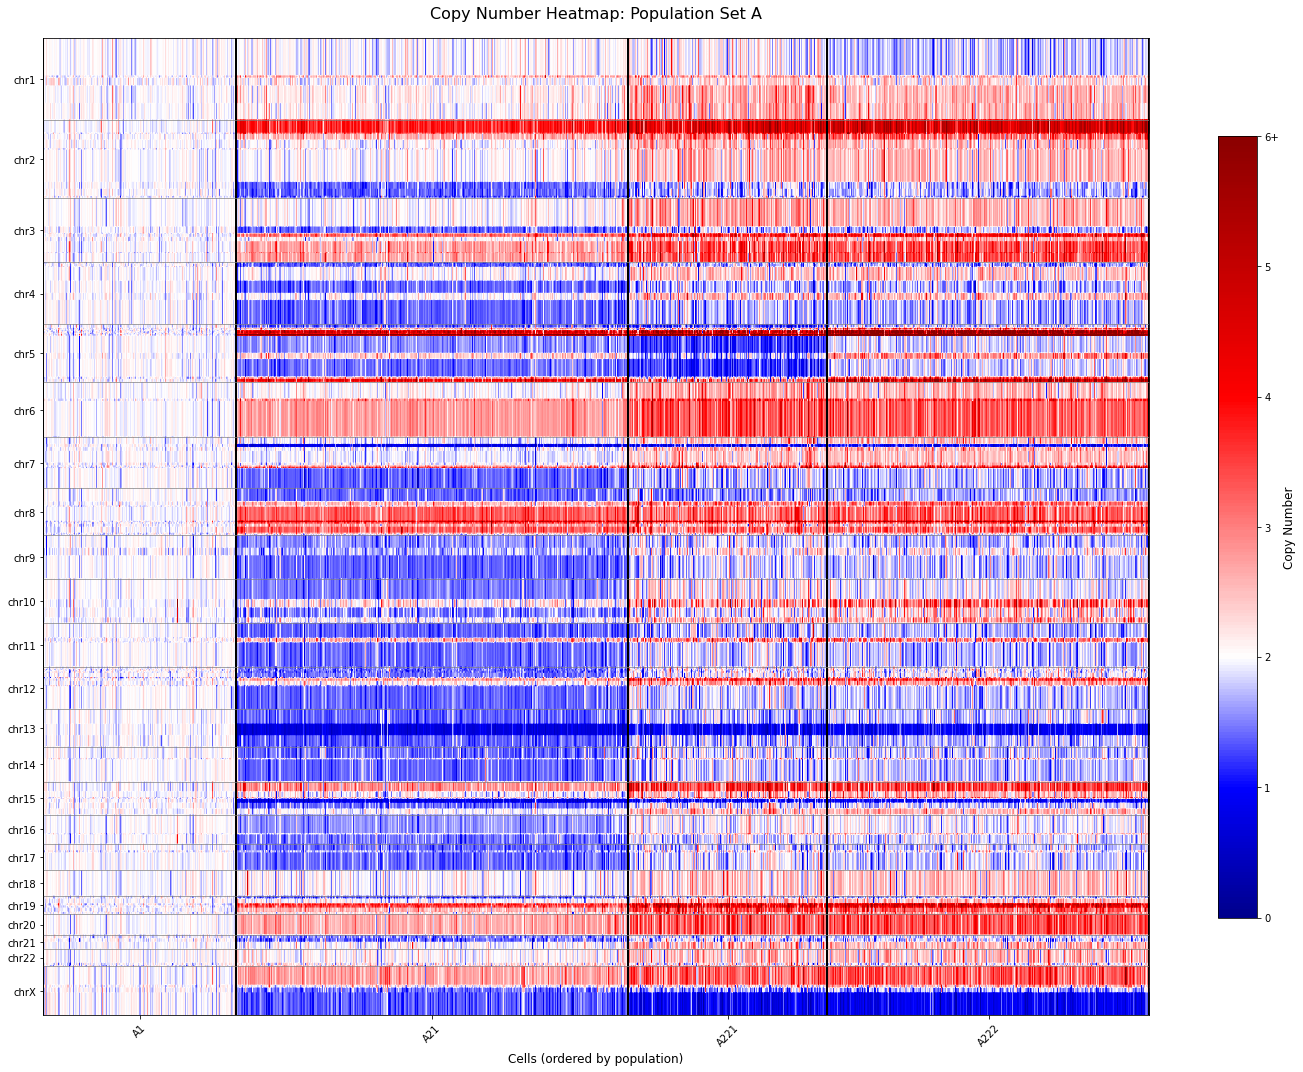

=== Creating Copy Number Heatmaps ===
Processing 124 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Heatmap B matrix dimensions: 124 segments × 1627 cells
Expanding heatmap from 124 segments to 5256 rows...

Chromosome representation in heatmap:
chr1: 438 rows, 245,459,747 bp total
chr2: 421 rows, 234,695,583 bp total
chr3: 346 rows, 193,355,005 bp total
chr4: 334 rows, 187,016,981 bp total
chr5: 311 rows, 173,502,285 bp total
chr6: 295 rows, 165,412,919 bp total
chr7: 276 rows, 154,658,822 bp total
chr8: 252 rows, 140,707,474 bp total
chr9: 234 rows, 131,151,738 bp total
chr10: 238 rows, 133,218,101 bp total
chr11: 236 rows, 132,149,408 bp total
chr12: 228 rows, 127,978,359 bp total
chr13: 202 rows, 113,350,205 bp total
chr14: 189 rows, 105,554,000 bp total
chr15: 176 rows, 98,373,534 bp total
chr16: 158 rows, 88,486,226 bp total
chr17: 142

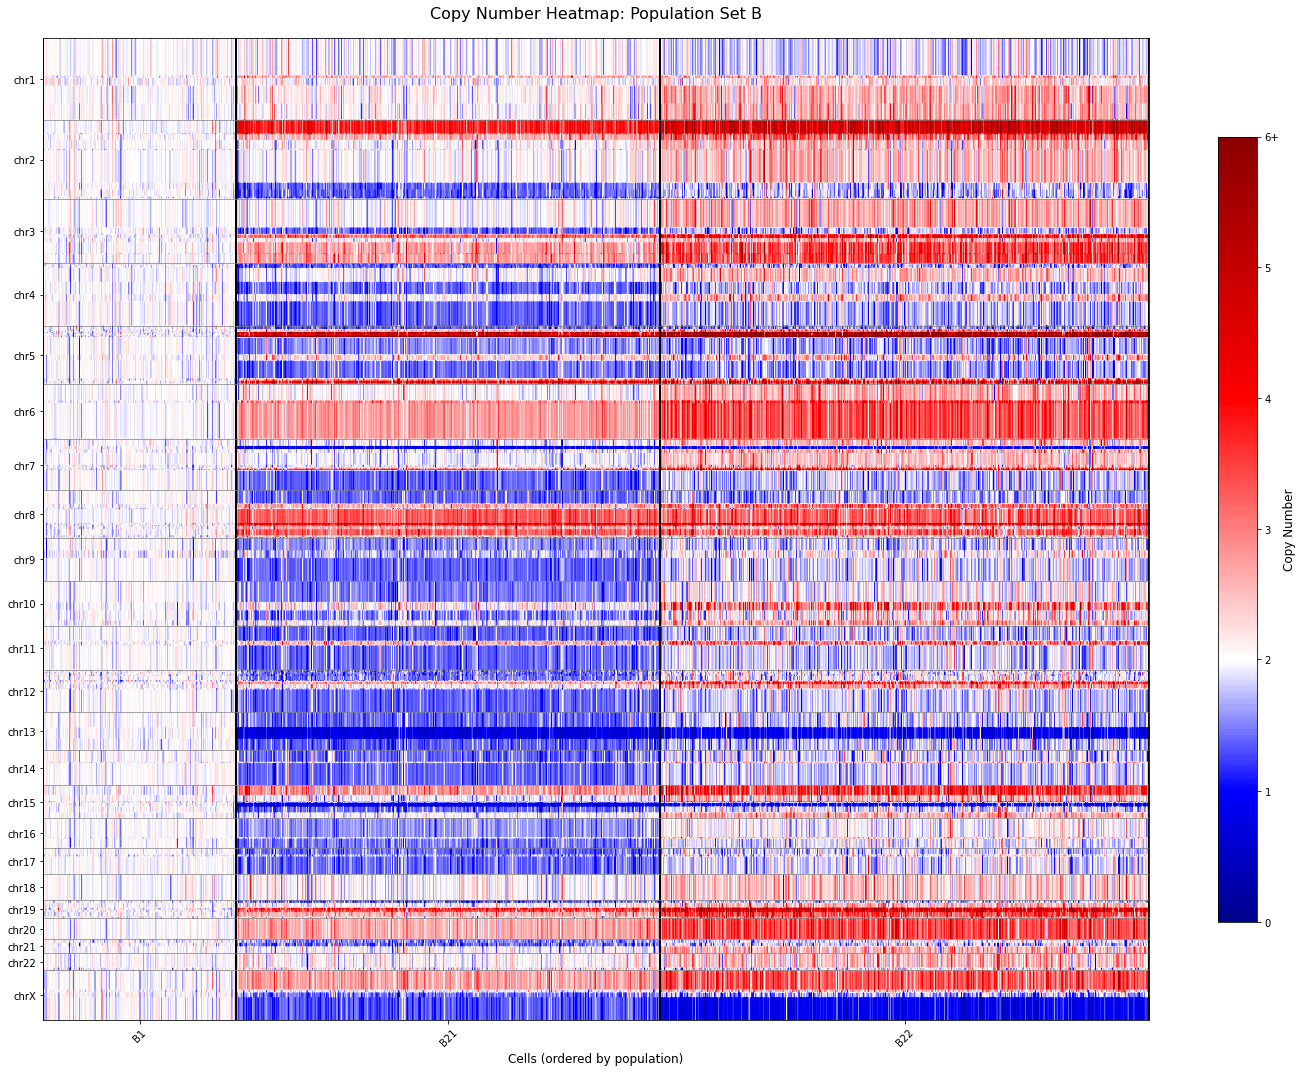

Processing 124 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Heatmap C matrix dimensions: 124 segments × 1627 cells
Expanding heatmap from 124 segments to 5256 rows...

Chromosome representation in heatmap:
chr1: 438 rows, 245,459,747 bp total
chr2: 421 rows, 234,695,583 bp total
chr3: 346 rows, 193,355,005 bp total
chr4: 334 rows, 187,016,981 bp total
chr5: 311 rows, 173,502,285 bp total
chr6: 295 rows, 165,412,919 bp total
chr7: 276 rows, 154,658,822 bp total
chr8: 252 rows, 140,707,474 bp total
chr9: 234 rows, 131,151,738 bp total
chr10: 238 rows, 133,218,101 bp total
chr11: 236 rows, 132,149,408 bp total
chr12: 228 rows, 127,978,359 bp total
chr13: 202 rows, 113,350,205 bp total
chr14: 189 rows, 105,554,000 bp total
chr15: 176 rows, 98,373,534 bp total
chr16: 158 rows, 88,486,226 bp total
chr17: 142 rows, 79,176,807 bp total
chr18: 138 

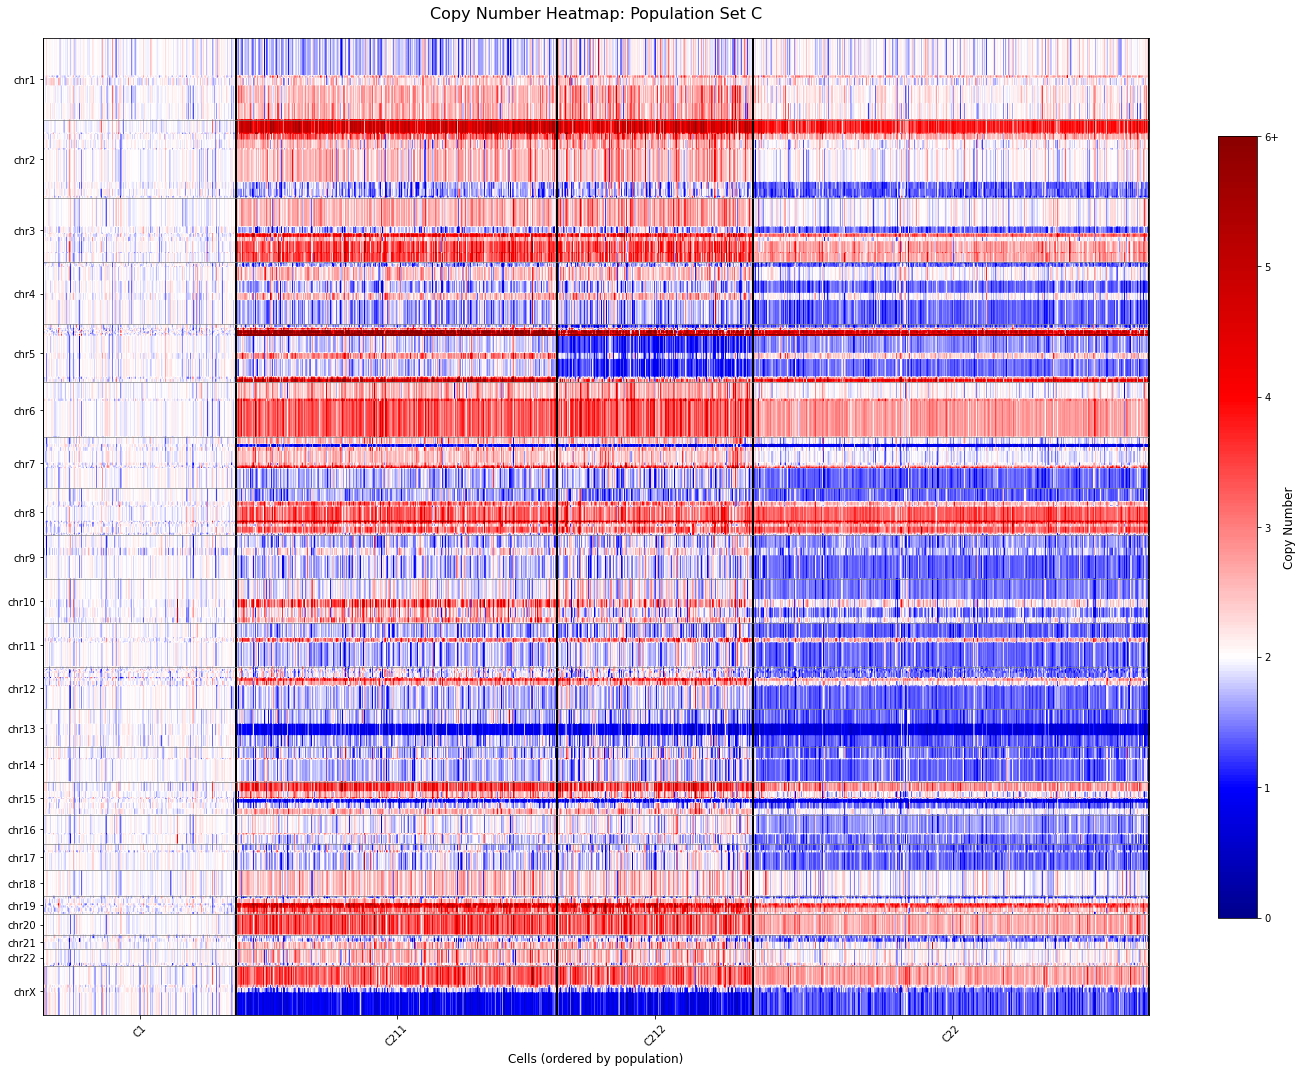

Processing 124 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Heatmap D matrix dimensions: 124 segments × 1627 cells
Expanding heatmap from 124 segments to 5256 rows...

Chromosome representation in heatmap:
chr1: 438 rows, 245,459,747 bp total
chr2: 421 rows, 234,695,583 bp total
chr3: 346 rows, 193,355,005 bp total
chr4: 334 rows, 187,016,981 bp total
chr5: 311 rows, 173,502,285 bp total
chr6: 295 rows, 165,412,919 bp total
chr7: 276 rows, 154,658,822 bp total
chr8: 252 rows, 140,707,474 bp total
chr9: 234 rows, 131,151,738 bp total
chr10: 238 rows, 133,218,101 bp total
chr11: 236 rows, 132,149,408 bp total
chr12: 228 rows, 127,978,359 bp total
chr13: 202 rows, 113,350,205 bp total
chr14: 189 rows, 105,554,000 bp total
chr15: 176 rows, 98,373,534 bp total
chr16: 158 rows, 88,486,226 bp total
chr17: 142 rows, 79,176,807 bp total
chr18: 138 

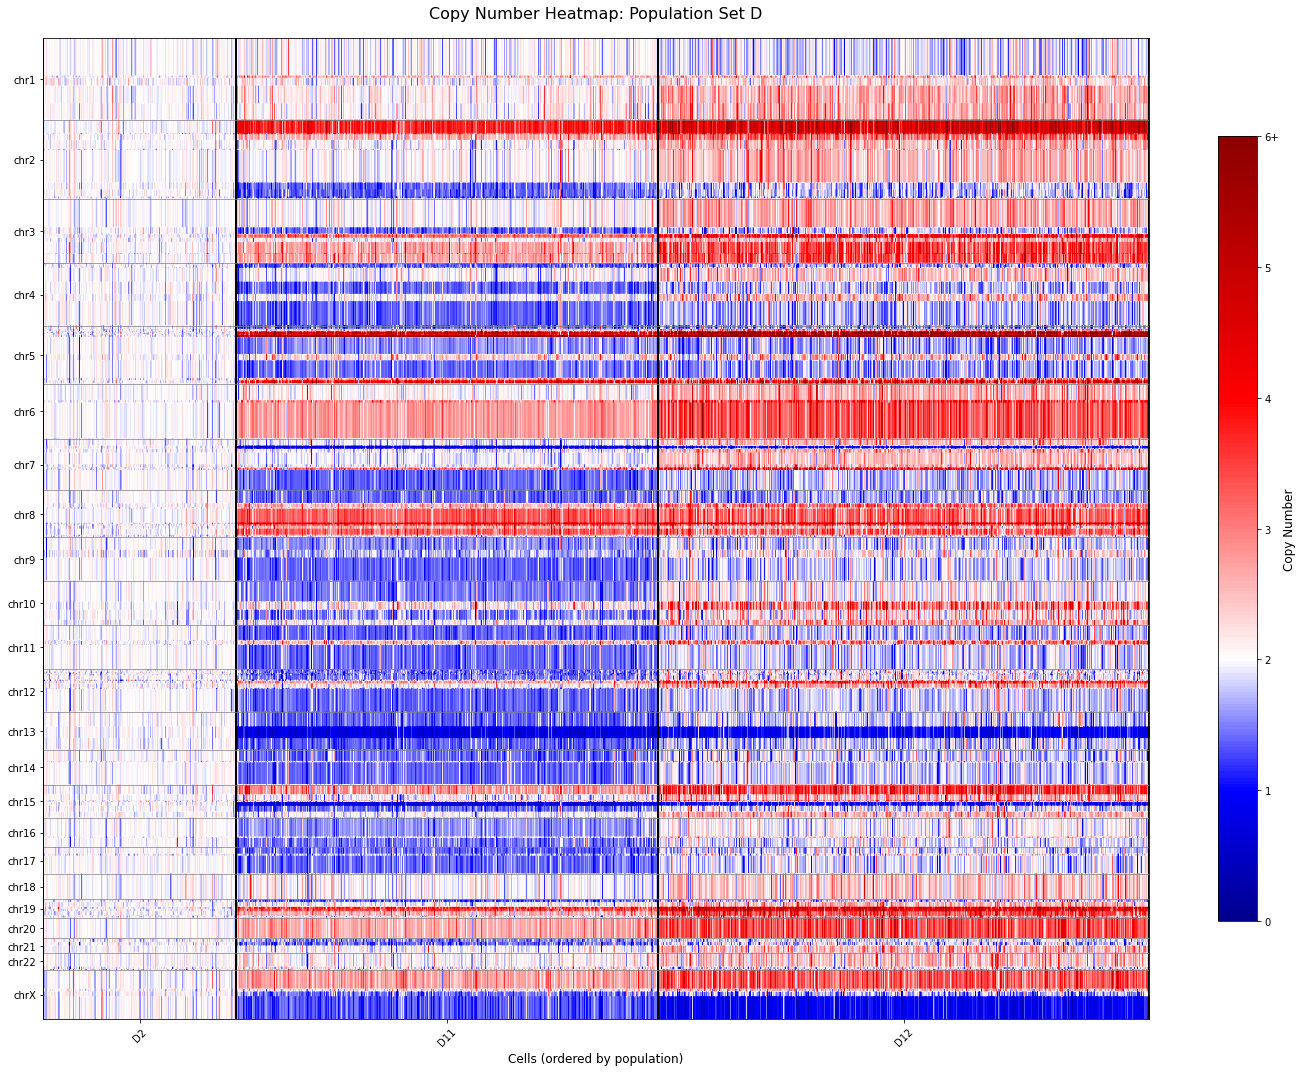

In [60]:
# Create heatmaps for both population sets
print("=== Creating Copy Number Heatmaps ===")

# For Population Set A
heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
    all_data, 
    A_dict, 
    ratios_A, 
    {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
    normal_A
)

print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)

print("=== Creating Copy Number Heatmaps ===")

heatmap_df_B, cell_mapping_B, boundaries_B, segment_info_B = create_copy_number_matrix_fast(
    all_data,
    B_dict,
    ratios_B,
    {f"{pop}_ratio": ploidy_results_B[pop]['optimal_multiplier'] for pop in ploidy_results_B.keys()},
    normal_B
)

print(f"Heatmap B matrix dimensions: {heatmap_df_B.shape[0]} segments × {heatmap_df_B.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_B,
    boundaries_B,
    segment_info_B,
    title="Copy Number Heatmap: Population Set B"
)


heatmap_df_C, cell_mapping_C, boundaries_C, segment_info_C = create_copy_number_matrix_fast(
    all_data,
    C_dict,
    ratios_C,
    {f"{pop}_ratio": ploidy_results_C[pop]['optimal_multiplier'] for pop in ploidy_results_C.keys()},
    normal_C
)

print(f"Heatmap C matrix dimensions: {heatmap_df_C.shape[0]} segments × {heatmap_df_C.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_C,
    boundaries_C,
    segment_info_C,
    title="Copy Number Heatmap: Population Set C"
)


heatmap_df_D, cell_mapping_D, boundaries_D, segment_info_D = create_copy_number_matrix_fast(
    all_data,
    D_dict,
    ratios_D,
    {f"{pop}_ratio": ploidy_results_D[pop]['optimal_multiplier'] for pop in ploidy_results_D.keys()},
    normal_D
)

print(f"Heatmap D matrix dimensions: {heatmap_df_D.shape[0]} segments × {heatmap_df_D.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_D,
    boundaries_D,
    segment_info_D,
    title="Copy Number Heatmap: Population Set D"
)

In [61]:
# Create population summary table for B
summary_rows_B = []

for pop_name in B_dict.keys():
    pop_cells = B_dict[pop_name]['cells']
    num_cells = len(pop_cells)

    pop_data = all_data[pop_cells]
    avg_read_count = pop_data.sum().sum() / num_cells

    relative_count = 2*relative_counts_B[pop_name]

    if pop_name != normal_B:
        results = ploidy_results_B[pop_name]
        local_minima = results['local_minima']
        optimal_m = results['optimal_multiplier']

        other_minima = [m for m, _ in local_minima if m != optimal_m]

        if other_minima:
            min_distance = min(abs(m - relative_count) for m in other_minima)
            closest_minima = [m for m in other_minima if abs(m - relative_count) == min_distance]
            second_best_m = min(closest_minima)
        else:
            second_best_m = optimal_m

    if pop_name in ploidy_results_B:
        relative_ploidy = optimal_m
    else:
        relative_ploidy = 2.0
        second_best_m = 2.0

    display_name = f"{pop_name} (normal)" if pop_name == normal_B else pop_name

    summary_rows_B.append({
        'pop_name': display_name,
        'num_cells': num_cells,
        'avg_read_count_per_cell': avg_read_count,
        'relative_counts': relative_counts_B[pop_name],
        'best_ploidy': relative_ploidy,
        'second_best': second_best_m
    })

population_summary_table_B = pd.DataFrame(summary_rows_B)
population_summary_table_B["rel_counts*2"] = population_summary_table_B["relative_counts"] * 2
population_summary_table_B

,pop_name,num_cells,avg_read_count_per_cell,relative_counts,best_ploidy,second_best,rel_counts*2
0,B1 (normal),284,67580.362676,1.000000,2.0,2.0,2.000000
1,B21,624,71194.551282,1.053480,2.2,2.8,2.106960
2,B22,719,82496.538248,1.220718,2.7,2.1,2.441435


In [62]:
# Create population summary table for C
summary_rows_C = []

for pop_name in C_dict.keys():
    pop_cells = C_dict[pop_name]['cells']
    num_cells = len(pop_cells)

    pop_data = all_data[pop_cells]
    avg_read_count = pop_data.sum().sum() / num_cells

    relative_count = 2*relative_counts_C[pop_name]
    
    if pop_name != normal_C:
        results = ploidy_results_C[pop_name]
        local_minima = results['local_minima']
        optimal_m = results['optimal_multiplier']

        other_minima = [m for m, _ in local_minima if m != optimal_m]

        if other_minima:
            min_distance = min(abs(m - relative_count) for m in other_minima)
            closest_minima = [m for m in other_minima if abs(m - relative_count) == min_distance]
            second_best_m = min(closest_minima)
        else:
            second_best_m = optimal_m
        print(pop_name)
        print(local_minima)
        print(optimal_m)
        print(relative_count)
        print(second_best_m)
    if pop_name in ploidy_results_C:
        relative_ploidy = optimal_m
    else:
        relative_ploidy = 2.0
        second_best_m = 2.0

    display_name = f"{pop_name} (normal)" if pop_name == normal_C else pop_name

    summary_rows_C.append({
        'pop_name': display_name,
        'num_cells': num_cells,
        'avg_read_count_per_cell': avg_read_count,
        'relative_counts': relative_counts_C[pop_name],
        'best_ploidy': relative_ploidy,
        'second_best': second_best_m
    })

population_summary_table_C = pd.DataFrame(summary_rows_C)
population_summary_table_C["rel_counts*2"] = population_summary_table_C["relative_counts"] * 2
population_summary_table_C

C211
[(2.700000000000001, 85531173.39380495), (5.600000000000003, 127885344.66184552), (3.700000000000002, 172758146.18429196), (4.900000000000003, 232328731.40322617), (4.400000000000002, 255052398.69946888)]
2.700000000000001
2.3945539151602198
3.700000000000002
C212
[(2.600000000000001, 155712959.4865231), (3.600000000000002, 173594991.5348838), (5.200000000000003, 195211671.00722694), (4.200000000000003, 221970892.27079216), (5.700000000000004, 241341762.6653588)]
2.600000000000001
2.478121035571708
3.600000000000002
C22
[(2.800000000000001, 63126887.09651129), (5.700000000000004, 133335919.2504247), (3.800000000000002, 155028651.34124672), (5.100000000000003, 244759453.18598038), (2.2000000000000006, 304451894.1215959)]
2.2000000000000006
2.1026260383017212
2.800000000000001


,pop_name,num_cells,avg_read_count_per_cell,relative_counts,best_ploidy,second_best,rel_counts*2
0,C1 (normal),284,67580.362676,1.000000,2.0,2.0,2.000000
1,C211,472,80912.411017,1.197277,2.7,3.7,2.394554
2,C212,289,83736.159170,1.239061,2.6,3.6,2.478121
3,C22,582,71048.115120,1.051313,2.2,2.8,2.102626


In [63]:
# Create population summary table for D
summary_rows_D = []

for pop_name in D_dict.keys():
    pop_cells = D_dict[pop_name]['cells']
    num_cells = len(pop_cells)

    pop_data = all_data[pop_cells]
    avg_read_count = pop_data.sum().sum() / num_cells

    relative_count = 2*relative_counts_D[pop_name]

    if pop_name != normal_D:
        results = ploidy_results_D[pop_name]
        local_minima = results['local_minima']
        optimal_m = results['optimal_multiplier']

        other_minima = [m for m, _ in local_minima if m != optimal_m]

        if other_minima:
            min_distance = min(abs(m - relative_count) for m in other_minima)
            closest_minima = [m for m in other_minima if abs(m - relative_count) == min_distance]
            second_best_m = min(closest_minima)
        else:
            second_best_m = optimal_m

    if pop_name in ploidy_results_D:
        relative_ploidy = optimal_m
    else:
        relative_ploidy = 2.0
        second_best_m = 2.0

    display_name = f"{pop_name} (normal)" if pop_name == normal_D else pop_name

    summary_rows_D.append({
        'pop_name': display_name,
        'num_cells': num_cells,
        'avg_read_count_per_cell': avg_read_count,
        'relative_counts': relative_counts_D[pop_name],
        'best_ploidy': relative_ploidy,
        'second_best': second_best_m
    })

population_summary_table_D = pd.DataFrame(summary_rows_D)
population_summary_table_D["rel_counts*2"] = population_summary_table_D["relative_counts"] * 2
population_summary_table_D

,pop_name,num_cells,avg_read_count_per_cell,relative_counts,best_ploidy,second_best,rel_counts*2
0,D11,620,70921.638710,1.049442,2.2,2.8,2.098883
1,D12,723,82668.042877,1.223255,2.7,2.1,2.446511
2,D2 (normal),284,67580.362676,1.000000,2.0,2.0,2.000000



Creating ploidy comparison for population: A21


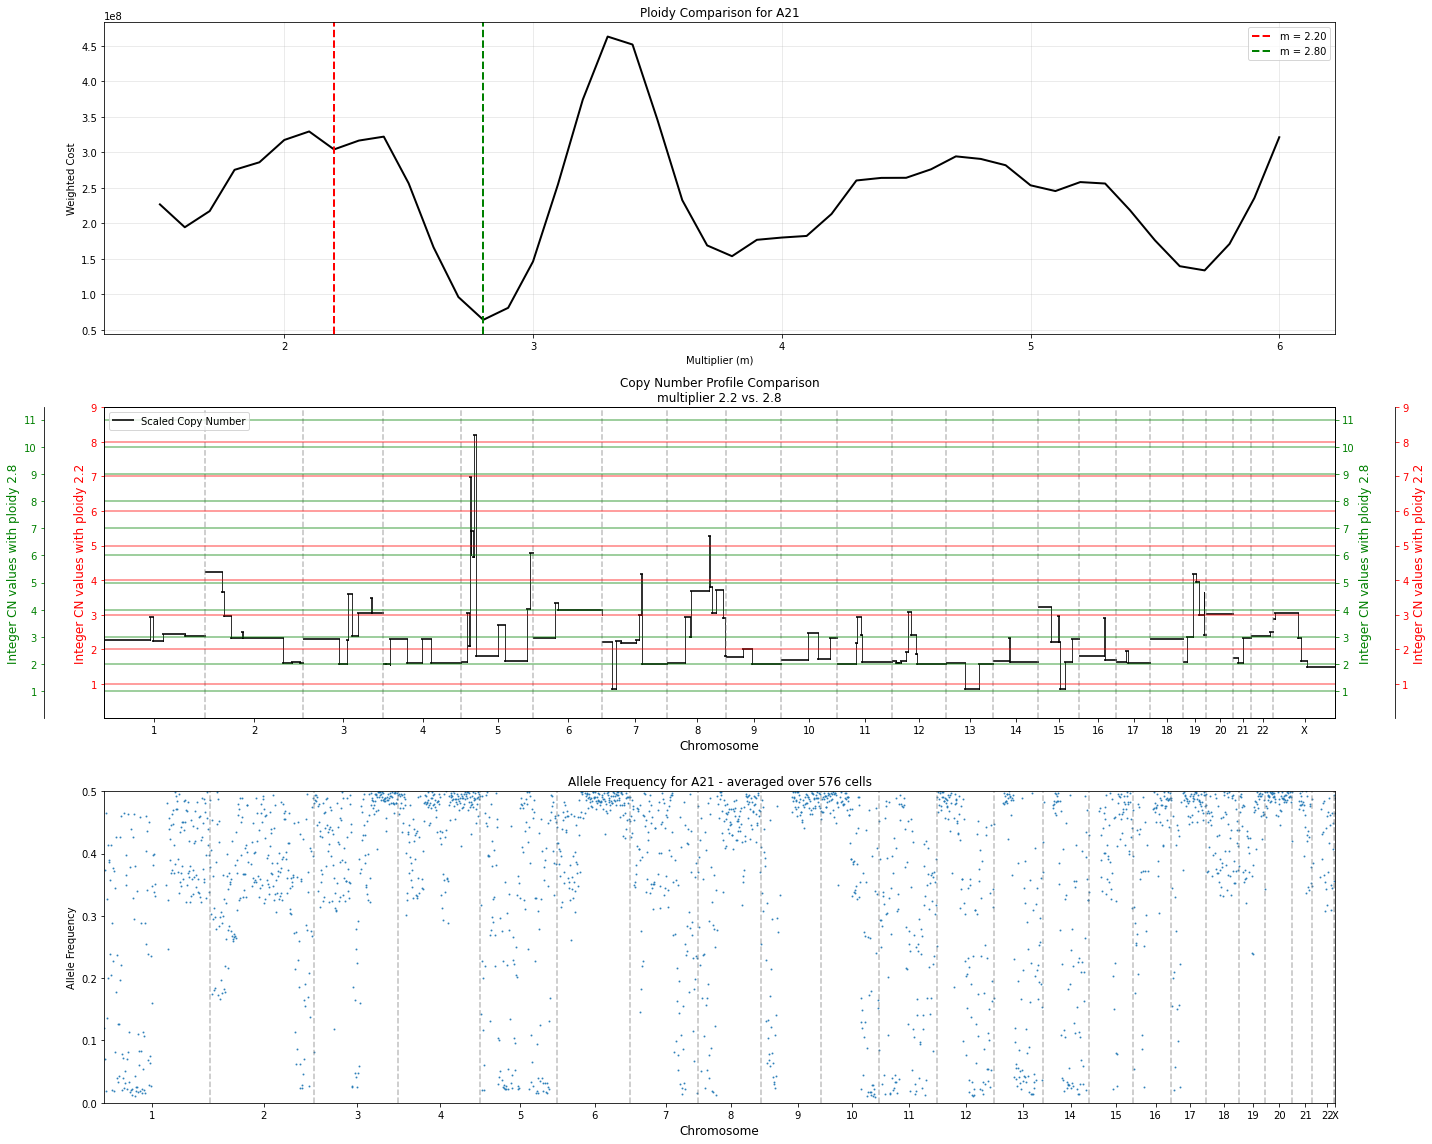

Compared 2.20 vs 2.80 for A21

Creating ploidy comparison for population: A221


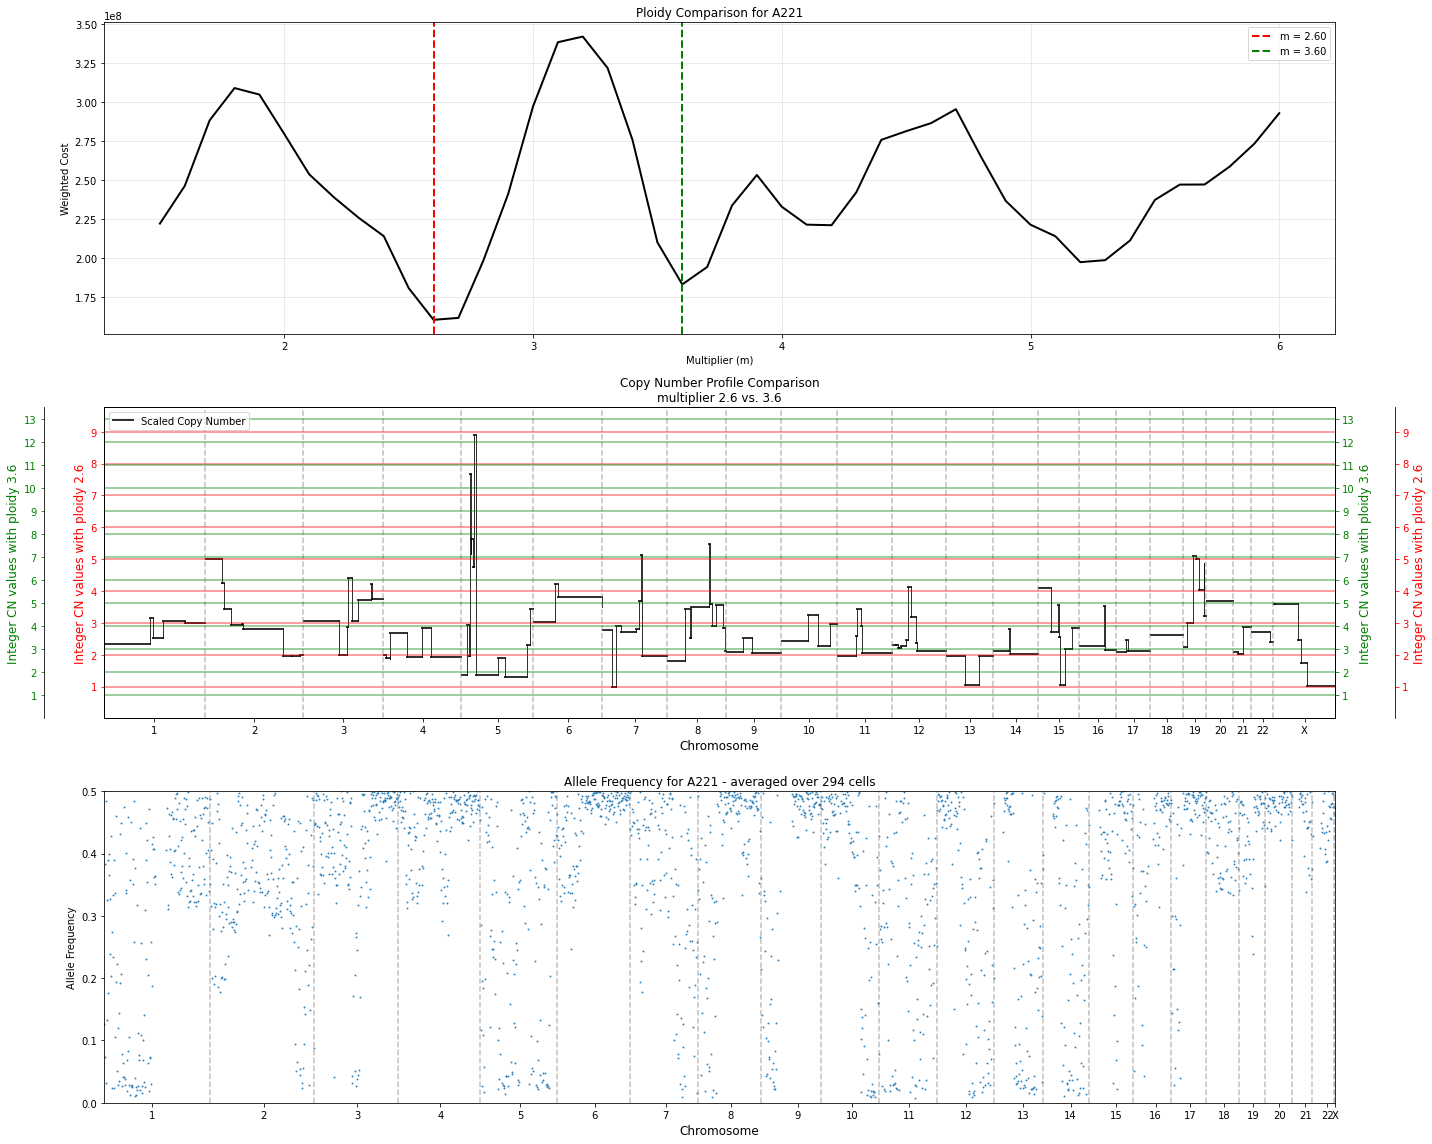

Compared 2.60 vs 3.60 for A221

Creating ploidy comparison for population: A222


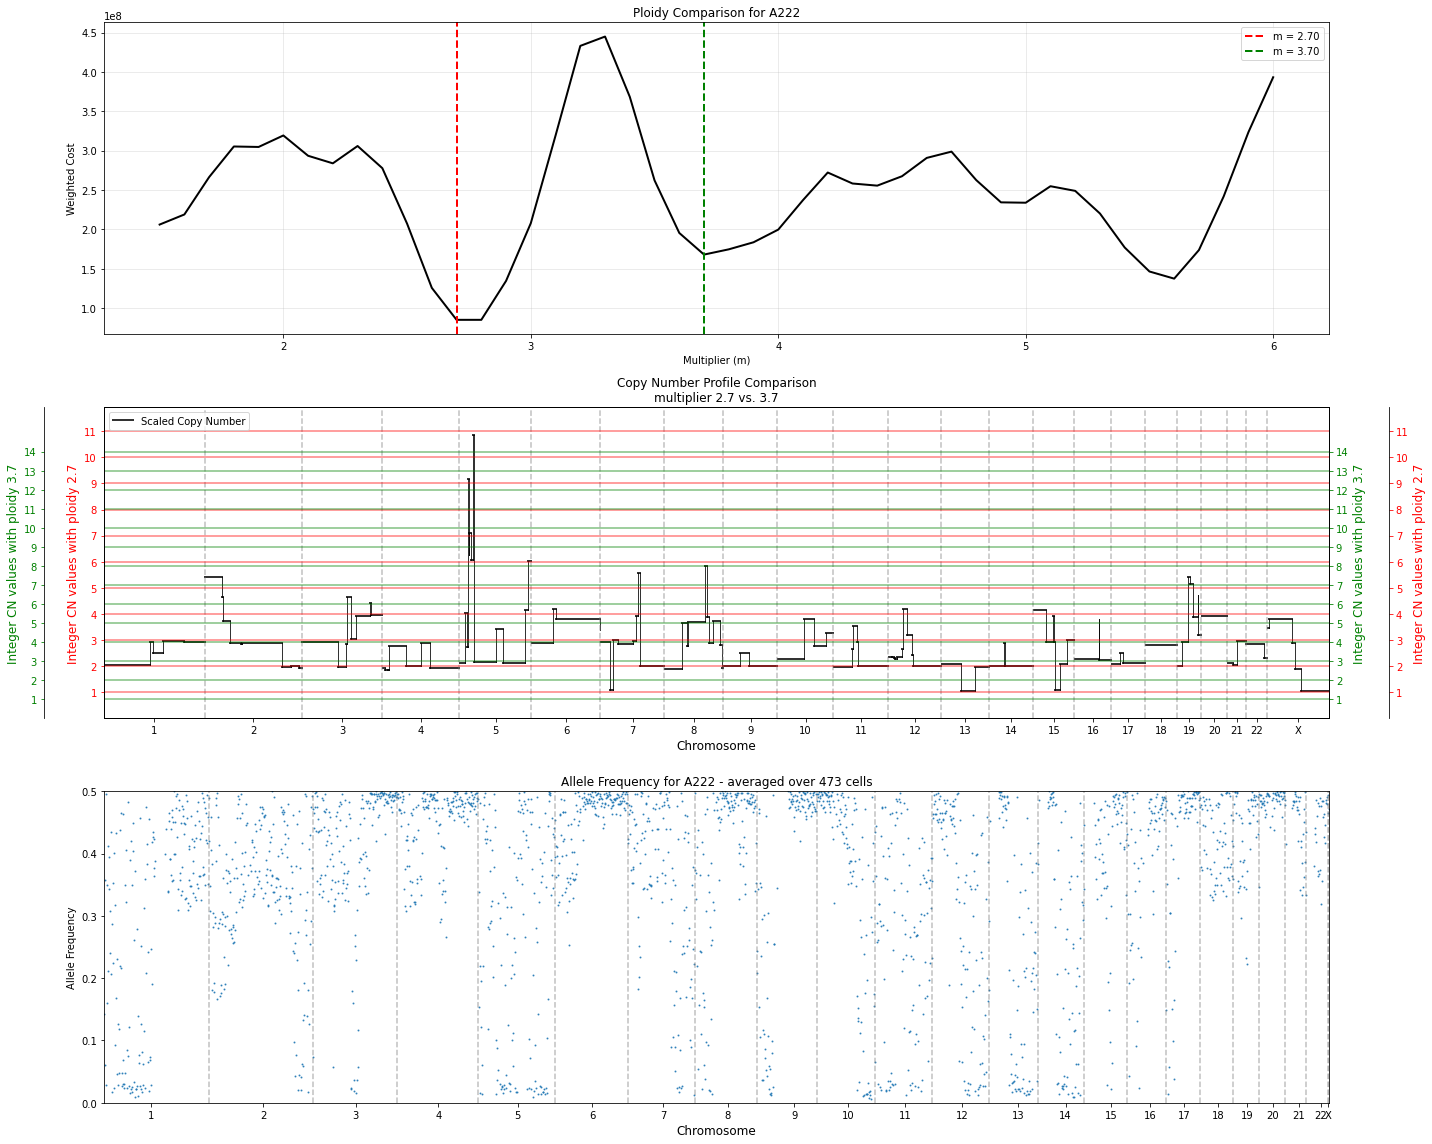

Compared 2.70 vs 3.70 for A222


In [64]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    relative_count = 2*relative_counts_A[pop_name]
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - relative_count) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - relative_count) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")


Creating ploidy comparison for population: B21


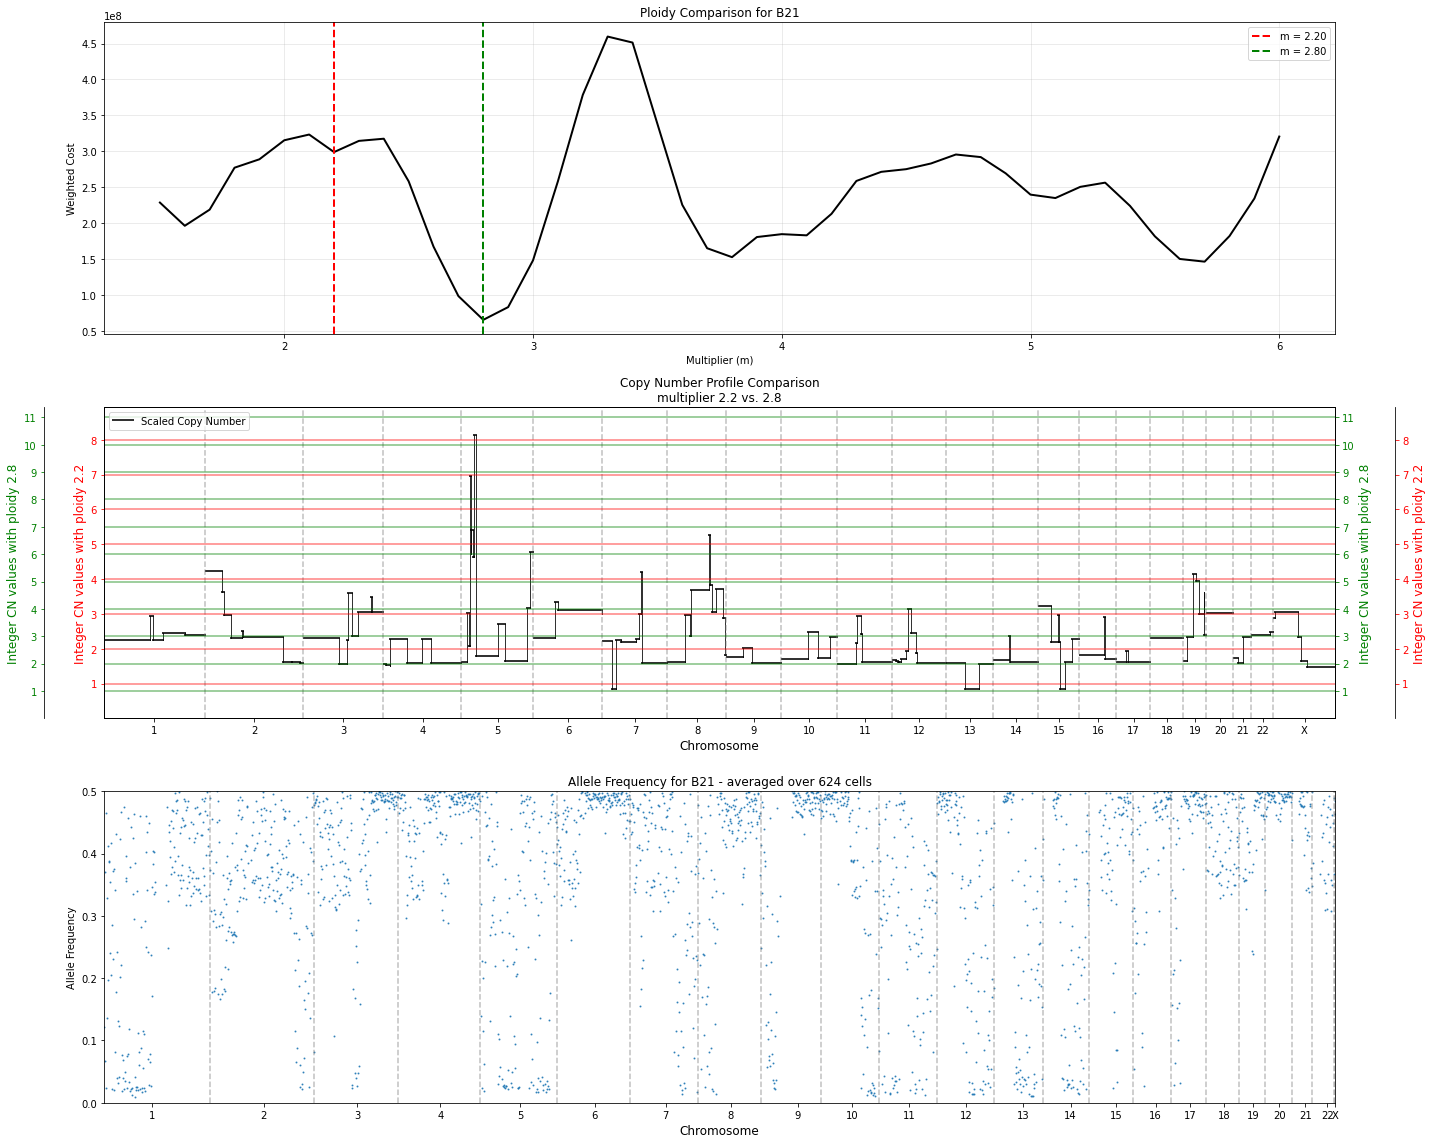

Compared 2.20 vs 2.80 for B21

Creating ploidy comparison for population: B22


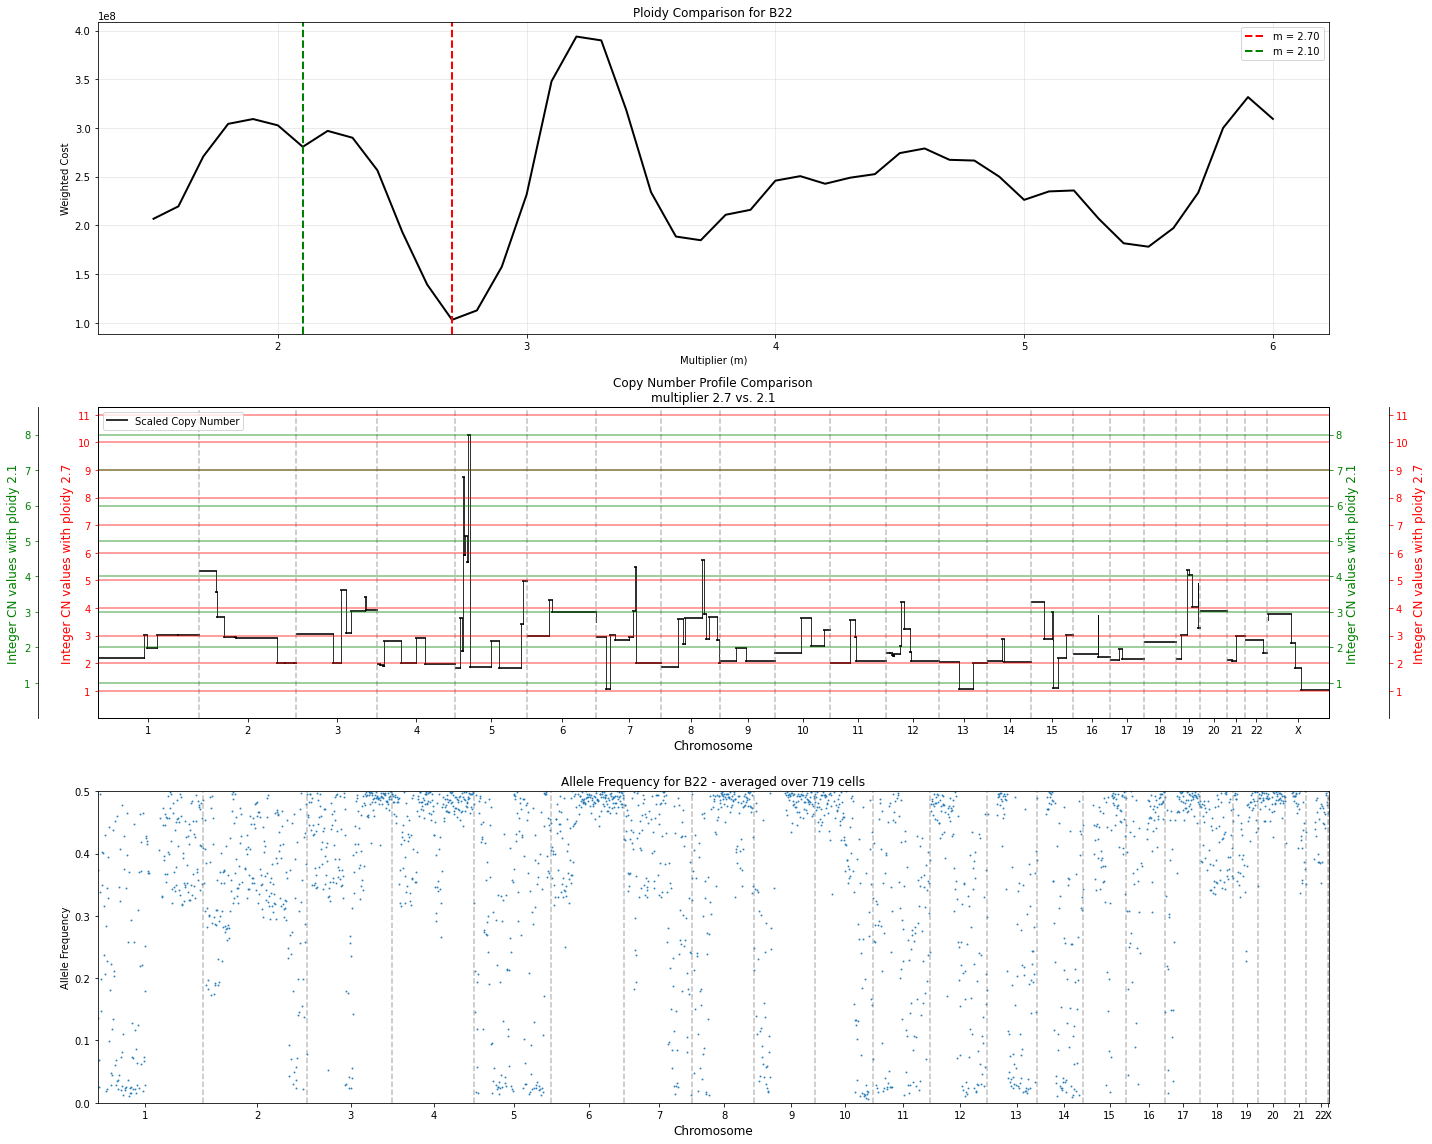

Compared 2.70 vs 2.10 for B22


In [65]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_B.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_B[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    relative_count = 2*relative_counts_B[pop_name]
    
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - relative_count) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - relative_count) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_B[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=B_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")


Creating ploidy comparison for population: C211


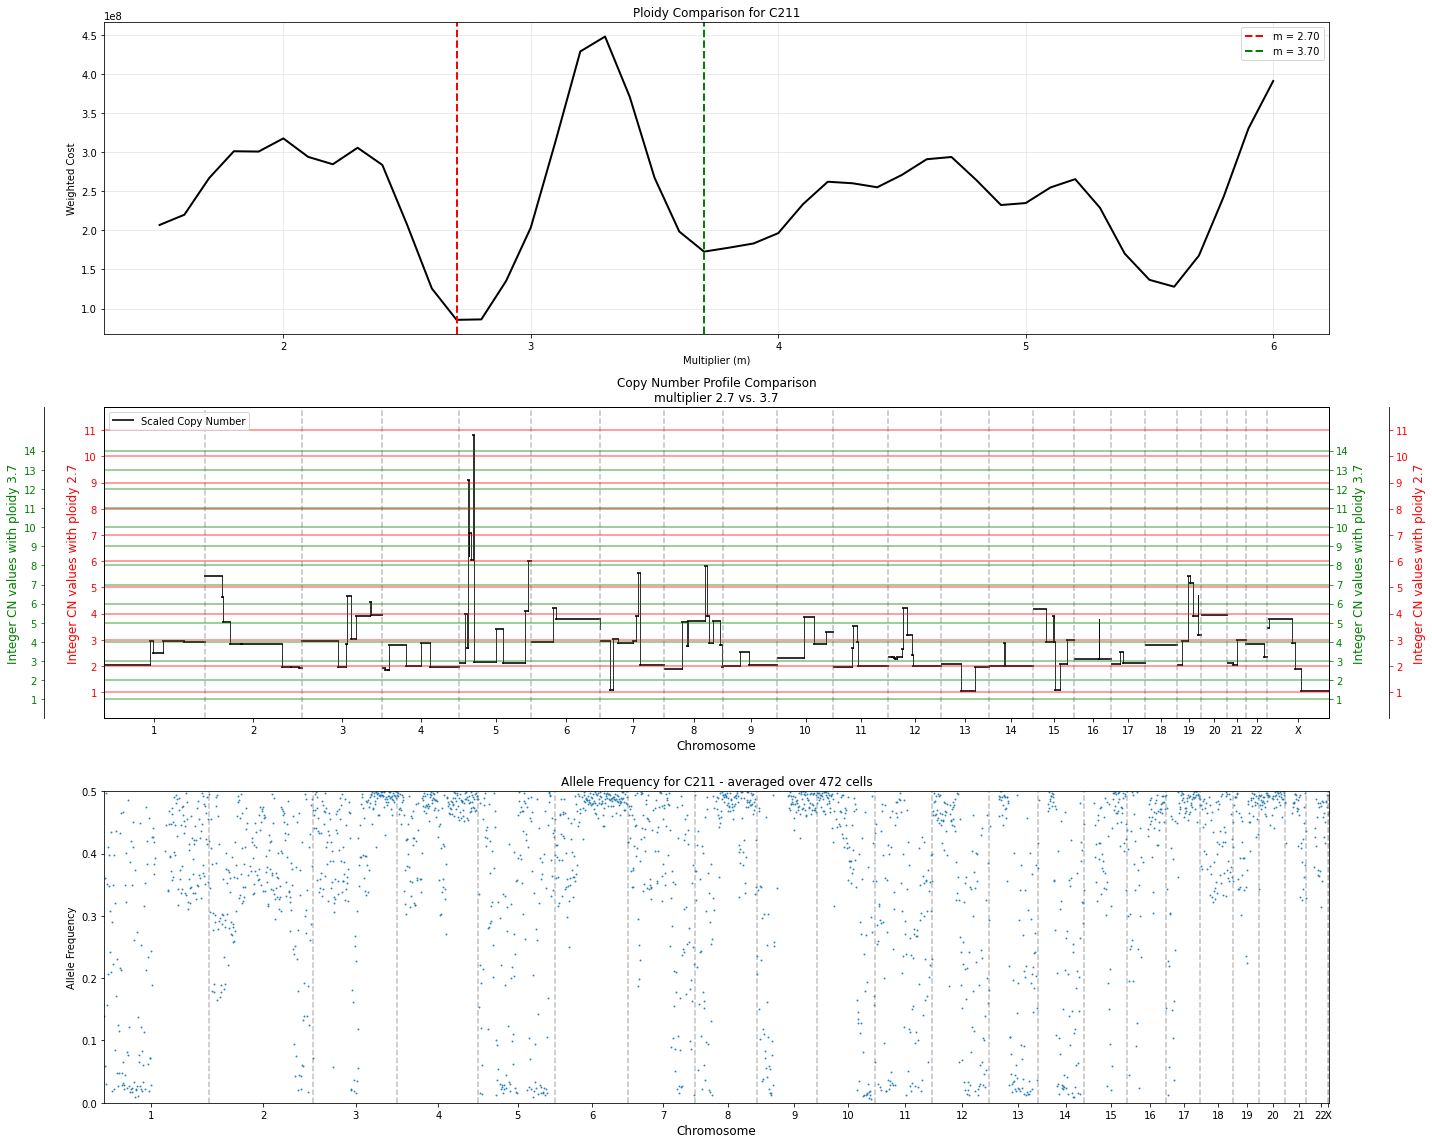

Compared 2.70 vs 3.70 for C211

Creating ploidy comparison for population: C212


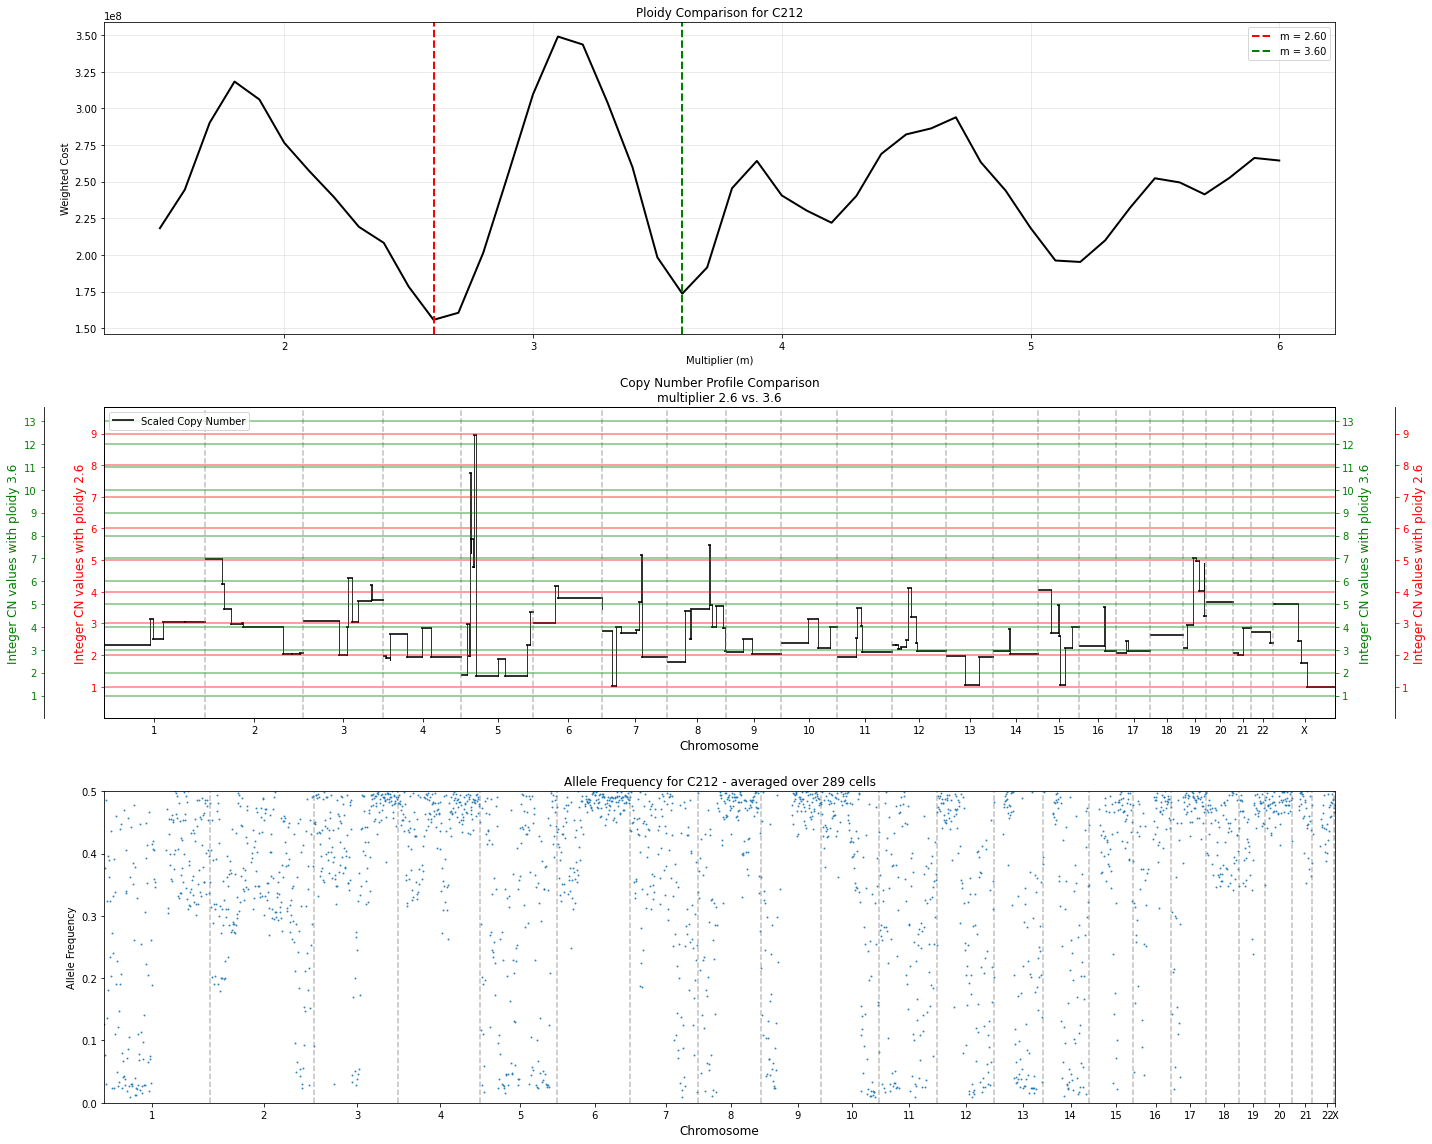

Compared 2.60 vs 3.60 for C212

Creating ploidy comparison for population: C22


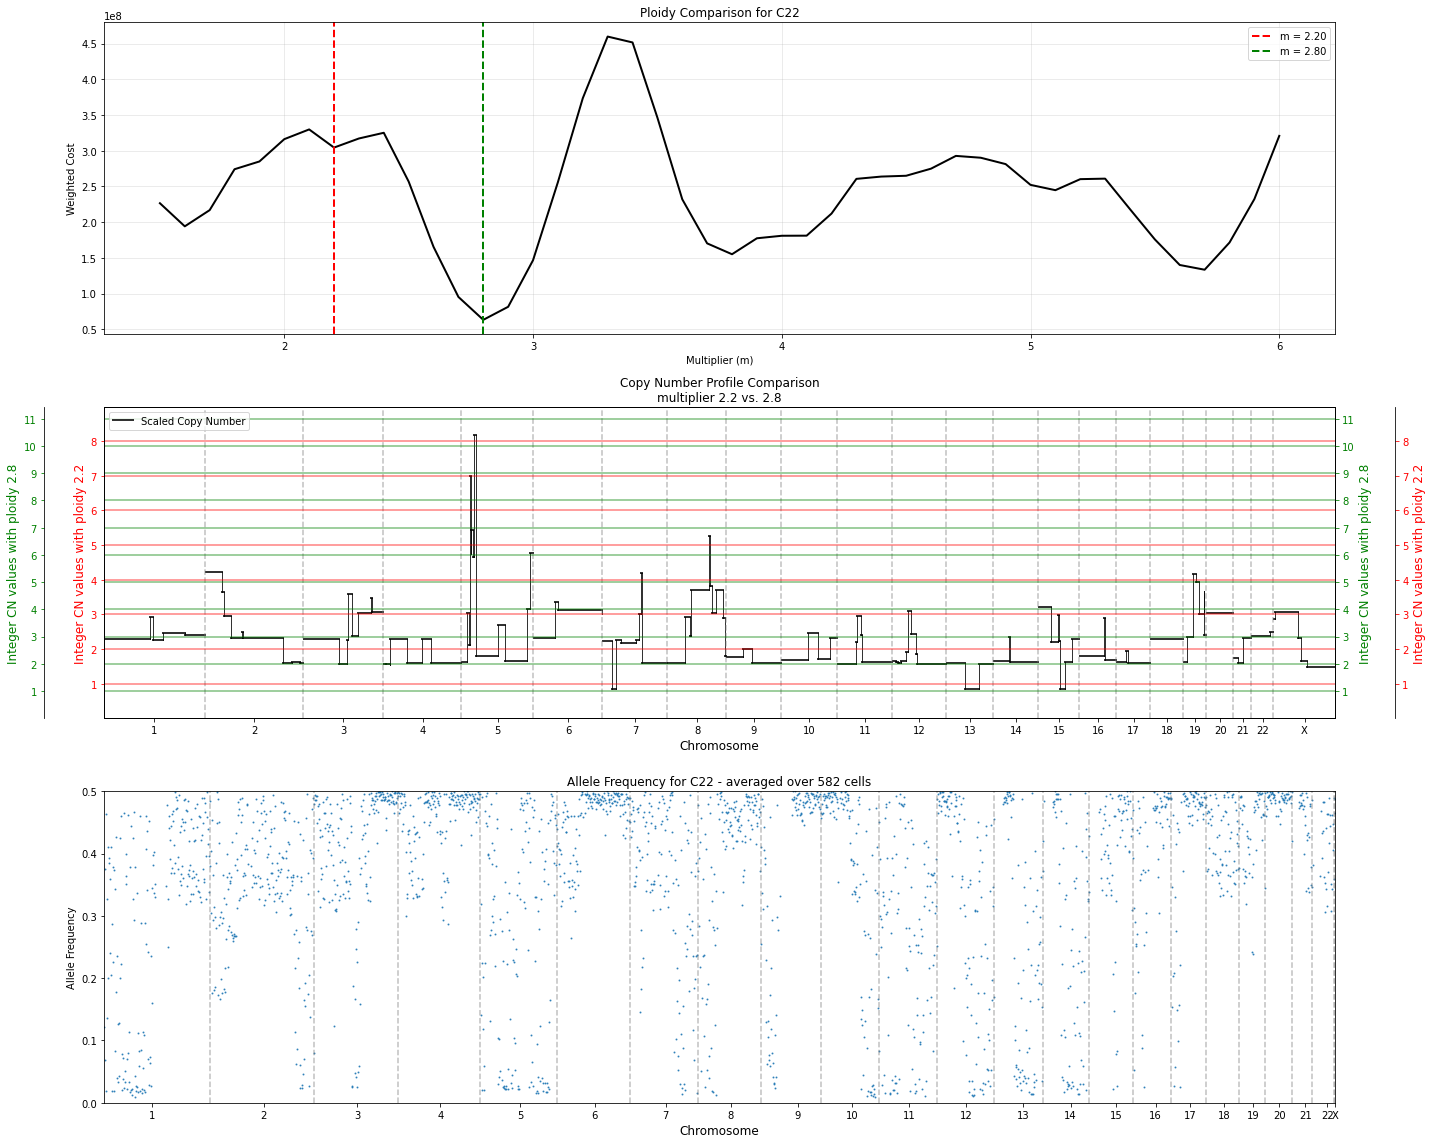

Compared 2.20 vs 2.80 for C22


In [66]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_C.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_C[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    relative_count = 2*relative_counts_C[pop_name]
    
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - relative_count) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - relative_count) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_C[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=C_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")

In [ ]:
population_summary_table_B.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_B.txt", sep="\t", index=False)
population_summary_table_C.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_C.txt", sep="\t", index=False)
population_summary_table_D.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_D.txt", sep="\t", index=False)